# Monitor de Fragilidad Fiscal Provincial — IFFS v2

**Materia:** Programación para Economistas — Segundo Parcial · **Autor/a:** Estudiante, UADE · **Actualizado:** septiembre 2026

Este notebook construye, audita, valida y explora el **Índice de Fragilidad Fiscal Subnacional (IFFS)** de las 24 jurisdicciones
argentinas (2005-2025), a partir de paneles fiscales y de deuda ya auditados en una investigación previa (Taller de Indicadores Económicos, 2026).

> **Qué es:** una herramienta de apoyo al análisis que ordena a las jurisdicciones por su fragilidad fiscal **relativa** (percentil dentro de cada año).
> **Qué no es:** una probabilidad de default, ni un sistema de alerta calibrado, ni un modelo predictivo.

**Cómo leer las etiquetas** que aparecen en todo el documento:
**[EVIDENCIA]** calculado en los datos · **[INTERPRETACIÓN]** lectura económica · **[SUPUESTO]** no verificado ·
**[DISEÑO]** decisión de construcción · **[LIMITACIÓN]** lo que no se puede concluir con los datos disponibles.

**Versión.** Esta es la versión 2 del índice (rediseño metodológico). La versión 1 (base fija 2005-2012, cuatro dimensiones promediadas, niveles de alerta 33/66/85)
se conserva solo como especificación de comparación (`LEG_A/B/C`) y en `outputs/_historico_v1/`.

## 1. Problema, objetivo y usuarios

**Problema económico.** Las provincias argentinas difieren en su margen fiscal. Ante un shock común (COVID-19, marzo 2020), **12 de las 24 jurisdicciones
reestructuraron deuda de mercado en 2020-2021**, y La Rioja incumplió el Bono Verde en 2025. No hay una herramienta pública, sistemática y actualizable que compare
la fragilidad fiscal *relativa* de las 24 provincias con datos oficiales y una metodología transparente.

**Objetivo general.** Construir una herramienta computacional que procese, armonice y visualice indicadores de fragilidad fiscal provincial, como apoyo —no reemplazo— al análisis económico.

**Objetivos específicos.**
1. Armonizar los paneles fiscales, de deuda y de servicio de deuda (2005-2025), **dejando visible la cobertura y lo que falta**.
2. Diseñar el índice con criterios económicos y estadísticos **independientes de los eventos de default**, y compararlo con alternativas (normalización, ventanas, pesos, extremos).
3. Separar **descripción, discriminación y anticipación** al validar, y declarar qué pruebas no son viables y por qué.
4. Presentar todo en un dashboard con las mismas cifras que este notebook.

**Usuarios.** Estudiantes e investigadores de finanzas públicas; periodistas y analistas que contextualicen deuda provincial; equipos técnicos que necesiten un insumo exploratorio.
**No** es para inversores que busquen una señal ni para calificación crediticia.

| Atributo | Descripción |
|---|---|
| Tipo de producto | Herramienta de análisis y monitoreo: notebook reproducible + dashboard Streamlit + informe + presentación |
| Categoría | Conjunto de subíndices + compuesto de posición relativa |
| Tecnología | Python (pandas, numpy, scipy, scikit-learn, matplotlib, plotly, Streamlit) |

## 2. Fuentes de datos

| Panel | Fuente | Cobertura | Archivo (`data/raw/base_investigacion/`) |
|---|---|---|---|
| Ejecución presupuestaria (ingresos, gastos, resultado) | DNAP | 2005-2025, 24 jurisdicciones | `panel_fiscal_provincial.csv`, `panel_fiscal_benchmarks.csv` |
| Stock de deuda por acreedor | DNAP | 1996-2025 | `deuda_provincial_panel_1996_2025.csv` |
| Servicio de deuda (amortización + interés) | DNAP | 2005-2025 (CABA corregida, ver §4) | `servicio_deuda_provincial_panel_2005_2025.csv` |
| Ratios deuda/ingresos y servicio/ingresos | cálculo propio | 2005-2025 | `deuda_ratios_provincia_anio.csv` |
| Composición de deuda por moneda | Bazza, Tedesca & Mahieu (2025) | 1996-2002 y 2014-2020, 11-13 de 24 | `deuda_moneda_panel.csv` |
| Capacidad de respuesta | BCRA | 2005-2025 | `capacidad_respuesta_panel.csv` |
| Eventos de default/reestructuración | DNAP (`reestructuracion_titulos_provinciales.pdf`) | 13 eventos | `eventos_estres_provincial.csv` |

**[LIMITACIÓN]** Los paneles de `base_investigacion/` son **derivados** de las fuentes oficiales; los archivos originales de la DNAP no están en el repositorio (salvo el de servicio de CABA y el de stock de La Pampa,
en `data/raw/fuentes_dnap/`). Este proyecto no reprocesa los Excel crudos.

In [1]:
import json
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
_cwd = Path.cwd()
PROJECT_ROOT = _cwd.parent if _cwd.name == "notebooks" else _cwd     # funciona desde notebooks/ o desde la raíz
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from IPython.display import Markdown as _Markdown

from src import analytics as an
from src import data_processing as dp
from src import indicators as ind
from src import modeling as mdl
from src import pipeline as pl
from src import validation as val
from src import visualization as viz
from src.formato import es

def Markdown(texto):    # Markdown con formato castellano (coma decimal) para los textos armados con cifras del JSON
    return _Markdown(es(texto))

import builtins

def print(*args, **kwargs):    # salidas de texto con coma decimal (castellano); los datos y tablas no se tocan
    builtins.print(*[es(a) if isinstance(a, str) else es(str(a)) if isinstance(a, (list, dict, tuple, float)) else a for a in args], **kwargs)

def _num_es(x):                # tablas: coma decimal y punto de miles
    return f"{x:,.3f}".replace(",", "X").replace(".", ",").replace("X", ".")

np.random.seed(42)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 150)
pd.set_option("display.float_format", _num_es)
FIG = PROJECT_ROOT / "outputs" / "figures"
TAB = PROJECT_ROOT / "outputs" / "tables"

def fig(nombre, ancho=900):
    display(Image(filename=str(FIG / f"{nombre}.png"), width=ancho))

def tabla(nombre):
    return pd.read_csv(TAB / f"{nombre}.csv")

def c(x, d=2):
    """Formato con coma decimal (texto en castellano)."""
    return f"{x:.{d}f}".replace(".", ",")

print("Raíz del proyecto:", PROJECT_ROOT)

Raíz del proyecto: /Users/caro/Library/CloudStorage/GoogleDrive-ralukita101@gmail.com/Mi unidad/JUANDE/CURSAR/05. Programación para economistas  economia computacional/parcial2_monitor_fragilidad_fiscal


### Fuente única de cifras
Las pruebas con remuestreo (bootstrap, permutaciones) tardan ~1 minuto. `scripts/generar_resultados.py` las calcula **una sola vez** (semilla fija 42), escribe `outputs/tables/*.csv`,
`outputs/figures/*.png` y `outputs/resultados_clave.json`, y de ahí leen **este notebook, el dashboard, el informe y la presentación**. Poner `RECALCULAR = False` reutiliza lo ya generado
(el notebook verifica que corresponda al código y a los datos actuales).

In [2]:
RECALCULAR = True

if RECALCULAR:
    sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
    import generar_resultados
    generar_resultados.main()

R = json.loads((PROJECT_ROOT / "outputs" / "resultados_clave.json").read_text(encoding="utf-8"))
assert R["huella"] == pl.huella_del_proyecto(), "outputs/ no corresponde al código/datos actuales: RECALCULAR = True"
print("Resultados coherentes con el código y los datos actuales (huella", R["huella"][:10] + ").")

OK: resultados_clave.json, tablas y figuras escritas. Huella: 139aef89cddb30ce735b1c69373dead3
Resultados coherentes con el código y los datos actuales (huella 139aef89cd).


## 3. Carga, armonización y cobertura
`data_processing.construir_panel_maestro()` arma el panel **completo** 24 jurisdicciones × 21 años = 504 filas. Los faltantes son explícitos (NaN); **nada se imputa**.
Se trata cada dato dudoso de forma visible: se conserva el valor original y se marca su estado (`stock_estado`).

In [3]:
T = pl.construir_todo("excluir")            # panel + índice + legado + perfiles + backtest (tratamiento principal de La Pampa)
panel, eventos = T["panel"], T["eventos"]
print("Filas:", len(panel), "| jurisdicciones:", panel.provincia.nunique(), "| años:", panel.anio.min(), "-", panel.anio.max())
print("Duplicados (provincia, año):", int(panel.duplicated(["provincia", "anio"]).sum()))
print()
print("Avisos de validación de datos:")
for a in T["avisos"]:
    print(" -", a)

Filas: 504 | jurisdicciones: 24 | años: 2005 - 2025
Duplicados (provincia, año): 0

Avisos de validación de datos:
 - La Pampa 2005-2017 (13 obs.): stock de deuda con posible error de unidades y SIN confirmación oficial -> tratado como faltante en el análisis principal (no se corrige ni se borra el original: ver `deuda_stock_total_fuente`).
 - Sin ejecución presupuestaria 2025 (La Pampa): dato no reportado, queda como faltante.


,provincia,anios_con_compuesto,anios_solvencia,anios_liquidez,anios_estructural,anios_coyuntural,anios_totales
10,La Pampa,7,7,20,20,20,21


**[EVIDENCIA]** El compuesto se calcula en **490 de 504** provincia-año (97,2%). Faltantes: {'La Pampa': '2005-2017 y 2025 (14 años)'}. Cobertura por variable (%): {'solvencia': 97,2, 'liquidez': 99,8, 'estructural': 99,8, 'coyuntural': 99,8}.

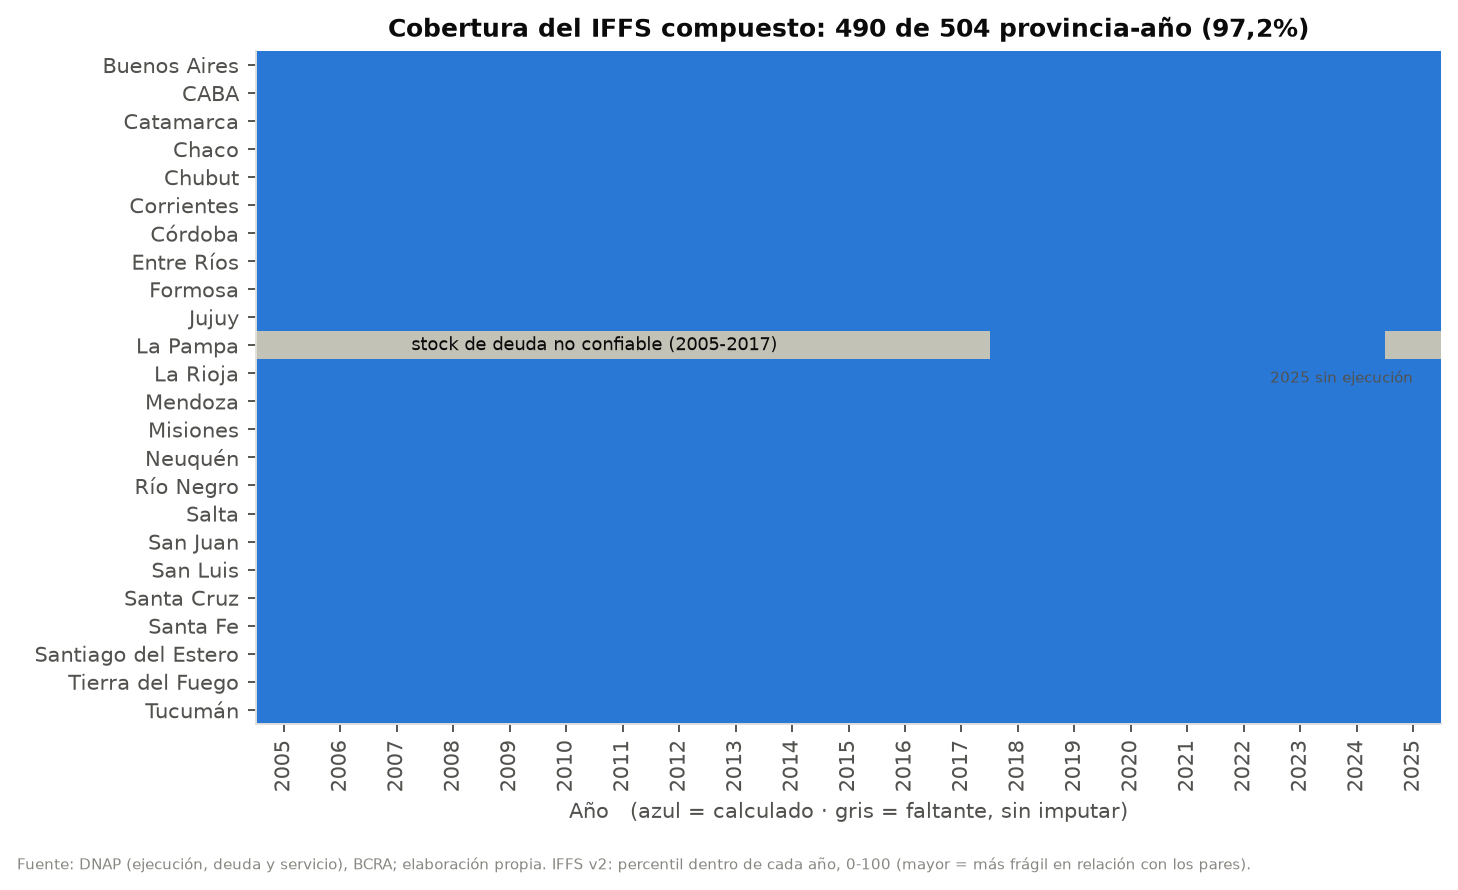

In [4]:
cob = tabla("T01_cobertura_por_provincia")
display(cob[cob.anios_con_compuesto < cob.anios_totales])
display(Markdown(f"**[EVIDENCIA]** El compuesto se calcula en **{R['cobertura']['n_compuesto']} de {R['cobertura']['n_total']}** provincia-año ({R['cobertura']['pct_compuesto']}%). "
                 f"Faltantes: {R['cobertura']['faltantes_compuesto']}. Cobertura por variable (%): {R['cobertura']['por_variable_pct']}."))
fig("cobertura_compuesto", 780)

## 4. Auditoría: qué se corrigió y qué se dejó marcado
El detalle completo está en `docs/FASE1_AUDITORIA.md` y se reproduce con `python auditoria/fase1_auditoria.py` (tablas en `outputs/auditoria/`). Resumen:

| Tema | Hallazgo | Tratamiento |
|---|---|---|
| **CABA — servicio de deuda** | **[EVIDENCIA]** El archivo trae dos hojas: `CABA` (en *miles*) y `Millones`. El procesamiento original leyó la primera y la trató como millones (error x1.000). | **Corregido**: se lee `Millones`, sin la columna `TOTAL`; el código **falla** si el cociente miles/millones no es exactamente 1.000. |
| **La Pampa — stock 2005-2017** | **[EVIDENCIA]** Como millones, La Pampa sería 6 veces la deuda de las otras 23 juntas en 1996 y 165 veces sus ingresos en 2005: imposible. La serie además salta de forma errática. **[SUPUESTO]** que esté en miles hasta 2017: **sin confirmación oficial**. | **No se corrige.** Se trata como **faltante** en el análisis principal; se conserva el original; la corrección ÷1.000 queda solo como **sensibilidad**. |
| Ejecución 2025 de La Pampa | Cero = dato no reportado. | Faltante. |
| Denominadores | Mezcla (resultado/ingresos totales; deuda y servicio/ingresos corrientes): **[EVIDENCIA]** sin efecto material (ρ de rangos ≈ 1,00). | Sin cambios. |
| Saltos de servicio (Santa Cruz 2024-25, San Luis 2014 y 2022, La Pampa 2024) | Contrastados con la **identidad stock-flujo** y la tasa de interés implícita (Fase 2, más abajo). | **[EVIDENCIA]** Santa Cruz y San Luis son amortizaciones reales; La Pampa 2024 no es verificable y no cambia ningún puesto. |

In [5]:
# CABA: la validación automática de unidades se ejecuta al cargar; si fallara, lanzaría ValueError.
serv_caba = dp.cargar_servicio_caba_millones()
caba = panel[panel.provincia == "CABA"]["servicio_sobre_ingresos"]
resto = panel[panel.provincia != "CABA"]["servicio_sobre_ingresos"]
print(f"CABA servicio/ingresos: mín {caba.min():.3f} · mediana {caba.median():.3f} · máx {caba.max():.3f}   (resto de las provincias: mediana {resto.median():.3f}, máx {resto.max():.3f})")
print("Antes de la corrección, CABA figuraba con servicio/ingresos de 45x a 75x sus ingresos (error x1.000).")

CABA servicio/ingresos: mín 0,023 · mediana 0,051 · máx 0,153   (resto de las provincias: mediana 0,037, máx 0,253)
Antes de la corrección, CABA figuraba con servicio/ingresos de 45x a 75x sus ingresos (error x1.000).


In [6]:
# La Pampa: tres tratamientos del stock 2005-2017 y su efecto sobre la escala
p_sin = dp.construir_panel_maestro(la_pampa="sin_tratar")
p_mil = dp.construir_panel_maestro(la_pampa="sensibilidad_miles")
lp = pd.DataFrame({
    "stock original (fuente)": panel.loc[panel.provincia == "La Pampa", "deuda_stock_total_fuente"].to_numpy(),
    "Deuda/Ingresos sin tratar": p_sin.loc[p_sin.provincia == "La Pampa", "deuda_sobre_ingresos"].to_numpy(),
    "Deuda/Ingresos en el análisis principal": panel.loc[panel.provincia == "La Pampa", "deuda_sobre_ingresos"].to_numpy(),
    "Deuda/Ingresos si fuera ÷1.000 (SUPUESTO)": p_mil.loc[p_mil.provincia == "La Pampa", "deuda_sobre_ingresos"].to_numpy(),
    "estado": panel.loc[panel.provincia == "La Pampa", "stock_estado"].to_numpy(),
}, index=panel.loc[panel.provincia == "La Pampa", "anio"].to_numpy())
display(lp.loc[2005:2020])
lpd = R["la_pampa"]
display(Markdown(f"**[EVIDENCIA]** El techo de Deuda/Ingresos en la ventana 2005-2012 es **{lpd['deuda_ingresos_max_base_sin_tratar']}x** con el dato sin tratar y **{lpd['deuda_ingresos_max_base_excluido']}x** sin La Pampa 2005-2017. "
                 f"**[DECISIÓN DE DISEÑO]** {lpd['tratamiento_principal']} ({lpd['obs_afectadas']} observaciones). "
                 f"**[SUPUESTO]** En el escenario ÷1.000, el IFFS de La Pampa 2005-2017 quedaría entre {lpd['escenario_supuesto_miles']['iffs_la_pampa_min']} y {lpd['escenario_supuesto_miles']['iffs_la_pampa_max']} "
                 f"y el AUC año por año cambia como máximo {lpd['escenario_supuesto_miles']['dif_max_auc_placebo_2005_2017']:.2f}: no cambia ninguna conclusión de este notebook."))

,stock original (fuente),Deuda/Ingresos sin tratar,Deuda/Ingresos en el análisis principal,Deuda/Ingresos si fuera ÷1.000 (SUPUESTO),estado
2005,"214.295,584","165,672",NaN,"0,166",no_confiable_excluido
2006,"192.380,589","117,790",NaN,"0,118",no_confiable_excluido
2007,"206.089,456","99,757",NaN,"0,100",no_confiable_excluido
2008,"196.584,791","77,297",NaN,"0,077",no_confiable_excluido
2009,"186.246,133","65,105",NaN,"0,065",no_confiable_excluido
2010,"174.847,866","45,006",NaN,"0,045",no_confiable_excluido
2011,"162.623,314","32,733",NaN,"0,033",no_confiable_excluido
2012,"150.298,341","23,444",NaN,"0,023",no_confiable_excluido
2013,"107.511,586","12,859",NaN,"0,013",no_confiable_excluido
2014,"82.818,464","7,263",NaN,"0,007",no_confiable_excluido


**[EVIDENCIA]** El techo de Deuda/Ingresos en la ventana 2005-2012 es **165,7x** con el dato sin tratar y **2,14x** sin La Pampa 2005-2017. **[DECISIÓN DE DISEÑO]** stock 2005-2017 tratado como faltante (no confiable, sin confirmación oficial) (13 observaciones). **[SUPUESTO]** En el escenario ÷1.000, el IFFS de La Pampa 2005-2017 quedaría entre 10,4 y 21,5 y el AUC año por año cambia como máximo 0,05: no cambia ninguna conclusión de este notebook.

**Fase 2 — saltos de servicio y unidades.** Dos pruebas internas (sin fuentes externas): la **identidad stock-flujo** (la amortización pagada debe ser del orden de la caída del stock) y la **tasa de interés implícita** (intereses / stock del año previo).
Un cociente cercano a 1.000 o a 0,001 delata una unidad distinta entre el archivo de stock y el de servicio.

In [7]:
su = R["servicio_unidades"]
display(Markdown(
    f"**[EVIDENCIA]** En las otras 23 jurisdicciones ({su['n_obs_identidad']} observaciones) la amortización/stock previo va de {c(su['amort_sobre_stock_p5_p95'][0], 3)} (p5) a {c(su['amort_sobre_stock_p5_p95'][1], 3)} (p95) y la tasa implícita de "
    f"{c(100*su['tasa_implicita_p5_p95'][0], 1)}% a {c(100*su['tasa_implicita_p5_p95'][1], 1)}%: **{su['n_sospechosas_fuera_la_pampa']}** observaciones compatibles con un error x1.000.\n\n"
    f"**Santa Cruz 2024-25:** el Fondo Fiduciario de Desarrollo Provincial pasa de {su['santa_cruz_ffdp_stock_2023_2024'][0]:,} a {su['santa_cruz_ffdp_stock_2023_2024'][1]} y la amortización de 2024 ({su['santa_cruz_ffdp_amortizacion_2024']:,}) lo cancela: bullet real. "
    f"**San Luis:** 2019-2022 la amortización coincide con la caída del stock (diferencia máxima {su['san_luis_max_diferencia_amort_vs_caida']}); el salto de 2014 ocurre sobre una base de 0,35 M$. "
    "**La Pampa 2024:** stock = 500 (cifra redonda) que no cierra con la amortización; no es verificable pero con el stock 2023 La Pampa sigue en el puesto 24 de 24 y ningún otro puesto cambia.\n\n"
    f"**[EVIDENCIA interna sobre La Pampa 2005-2017, NO confirmación oficial]** Con el stock en miles, la tasa implícita 2006-2015 es de {c(100*su['la_pampa_tasa_2006_2015_mediana_si_miles'], 1)}% (mediana); con el stock como viene, {c(100*su['la_pampa_tasa_2006_2015_mediana_si_millones'], 4)}%. "
    "Los stocks 2016-2017 (555.836 y 33.436) son inconsistentes con los intereses de 2017-2018 bajo cualquier unidad. Refuerza la hipótesis de miles, pero **el tratamiento principal (faltante) no cambia** hasta contar con la confirmación de la DNAP."))
display(pd.read_csv(PROJECT_ROOT / "outputs" / "auditoria" / "I2_la_pampa_tasa_implicita_por_hipotesis.csv").round(4))

**[EVIDENCIA]** En las otras 23 jurisdicciones (460 observaciones) la amortización/stock previo va de 0,016 (p5) a 0,329 (p95) y la tasa implícita de 0,3% a 20,7%: **0** observaciones compatibles con un error x1.000.

**Santa Cruz 2024-25:** el Fondo Fiduciario de Desarrollo Provincial pasa de 18,922 a 0 y la amortización de 2024 (36,472) lo cancela: bullet real. **San Luis:** 2019-2022 la amortización coincide con la caída del stock (diferencia máxima 0,0); el salto de 2014 ocurre sobre una base de 0,35 M$. **La Pampa 2024:** stock = 500 (cifra redonda) que no cierra con la amortización; no es verificable pero con el stock 2023 La Pampa sigue en el puesto 24 de 24 y ningún otro puesto cambia.

**[EVIDENCIA interna sobre La Pampa 2005-2017, NO confirmación oficial]** Con el stock en miles, la tasa implícita 2006-2015 es de 4,6% (mediana); con el stock como viene, 0,0050%. Los stocks 2016-2017 (555.836 y 33.436) son inconsistentes con los intereses de 2017-2018 bajo cualquier unidad. Refuerza la hipótesis de miles, pero **el tratamiento principal (faltante) no cambia** hasta contar con la confirmación de la DNAP.

,anio,tasa_si_stock_en_miles,tasa_si_stock_en_millones,tasa_referencia_resto_p5,tasa_referencia_resto_p95
0,2006,"0,052","0,000","0,003","0,207"
1,2007,"0,054","0,000","0,003","0,207"
2,2008,"0,047","0,000","0,003","0,207"
3,2009,"0,046","0,000","0,003","0,207"
4,2010,"0,045","0,000","0,003","0,207"
5,2011,"0,044","0,000","0,003","0,207"
6,2012,"0,042","0,000","0,003","0,207"
7,2013,"0,041","0,000","0,003","0,207"
8,2014,"0,057","0,000","0,003","0,207"
9,2015,"0,068","0,000","0,003","0,207"


In [8]:
h1 = pd.read_csv(PROJECT_ROOT / "outputs" / "auditoria" / "H1_controles_integridad.csv")
display(h1)

,control,resultado,detalle
0,Grilla completa 24 jurisdicciones x 21 años,OK,(504 filas)
1,"Sin duplicados (provincia, año)",OK,NaN
2,Sin duplicados en panel_fiscal_benchmarks.csv,OK,(0)
3,Sin duplicados en deuda_ratios_provincia_anio.csv,OK,(0)
4,Sin duplicados en capacidad_respuesta_panel.csv,OK,(0)
5,Sin valores negativos en deuda_sobre_ingresos,OK,NaN
6,Sin valores negativos en servicio_sobre_ingresos,OK,NaN
7,Sin valores negativos en rigidez_gastototal,OK,NaN
8,"Rigidez del gasto en [0,1]",OK,NaN
9,Ingresos corrientes estrictamente positivos do...,OK,NaN


## 5. Diseño metodológico

### 5.1 Las cuatro dimensiones y su significado económico
| Subíndice | Variable | Pregunta económica | Dirección |
|---|---|---|---|
| **Solvencia** | Deuda / Ingresos corrientes | ¿Cuánto pesa el stock de deuda frente a la capacidad de pago? | ↑ más frágil |
| **Liquidez** | Servicio de deuda / Ingresos corrientes | ¿Cuánta caja absorben amortización e intereses? | ↑ |
| **Estructural** | Gasto en personal / Gasto total | ¿Cuánto del gasto es difícil de ajustar? **[INTERPRETACIÓN]** ambigua: puede ser provisión de servicios, no rigidez | ↑ |
| **Coyuntural** | −Resultado financiero / Ingresos | ¿Hay un déficit este año? | ↑ |

Quedan **fuera** (y documentado): dependencia de transferencias nacionales (ambigüedad teórica: estabiliza o expone; no se resuelve sin mirar el outcome), moneda de la deuda (11 de 24 provincias),
y los depósitos del BCRA como "liquidez fiscal" (son depósitos del sistema bancario provincial, no caja del Tesoro).

### 5.2 ¿Índice único o subíndices? Criterios **sin usar eventos**

In [9]:
props = tabla("T02_propiedades_variables")[["dimension", "detalle", "icc", "ar1_intra", "persistencia_rangos", "mediana", "asimetria"]]
display(props)
print("icc = parte de la varianza que es diferencia PERMANENTE entre provincias · ar1_intra = persistencia de los desvíos dentro de cada provincia")
print("persistencia_rangos = correlación de Spearman entre los rangos de t y t+1 (media sobre años)")
display(tabla("T04_redundancia_subindices"))
print("Varianza explicada por los componentes principales de los 4 subíndices:", [round(x, 2) for x in R["diseno"]["pca_varianza"]])

,dimension,detalle,icc,ar1_intra,persistencia_rangos,mediana,asimetria
0,solvencia,Deuda / Ingresos corrientes,"0,301","0,905","0,960","0,309","1,700"
1,liquidez,Servicio de deuda / Ingresos corrientes,"0,282","0,813","0,892","0,038","1,195"
2,estructural,Gasto en personal / Gasto total,"0,636","0,789","0,929","0,450","0,036"
3,coyuntural,−Resultado financiero / Ingresos,"0,219","0,355","0,483","0,004","-0,095"
4,contexto,Ingresos de origen nacional / Ingresos corrien...,"0,968","0,649","0,982","0,585","-0,607"


icc = parte de la varianza que es diferencia PERMANENTE entre provincias · ar1_intra = persistencia de los desvíos dentro de cada provincia
persistencia_rangos = correlación de Spearman entre los rangos de t y t+1 (media sobre años)


,par,pooled,entre_provincias,intra_provincia,n
0,Solvencia – Liquidez,"0,788","0,895","0,707",490
1,Solvencia – Estructural,"0,180","0,383","-0,243",490
2,Solvencia – Coyuntural,"0,083","0,359","-0,080",490
3,Liquidez – Estructural,"0,219","0,586","-0,236",503
4,Liquidez – Coyuntural,"0,063","0,454","-0,117",503
5,Estructural – Coyuntural,"0,282","0,372","0,214",503


Varianza explicada por los componentes principales de los 4 subíndices: [0,54, 0,23, 0,18, 0,06]


**Lectura.**
- **[EVIDENCIA]** Las variables tienen dinámicas distintas: la rigidez del gasto es en buena parte un rasgo permanente (ICC 0,64); el resultado fiscal es 78% transitorio (ICC 0,22) y casi no persiste (AR(1) 0,36; persistencia de rangos 0,48).
- **[EVIDENCIA]** Solvencia y liquidez se parecen mucho **entre** provincias (ρ ≈ 0,9) pero bastante menos **en el tiempo** (ρ ≈ 0,7); la rigidez se correlaciona *negativamente* con ambas dentro de cada provincia. Un solo factor explica ~54% de la varianza: resumir en un número pierde información.
- **[INTERPRETACIÓN]** Cada dimensión sugiere una política distinta (reperfilar deuda ≠ ajustar gasto ≠ cubrir un déficit transitorio). Un índice único las vuelve compensables entre sí.

**[DISEÑO] Decisión:** subíndices como producto principal y un **compuesto** = media simple de solvencia, liquidez y estructural.

### 5.3 Regla ex ante para ventanas y composición
Se fijó **antes de mirar ningún evento**: una dimensión entra al compuesto si la persistencia de rangos de su forma anual es ≥ 0,85; y la ventana de suavizado de cada variable es la más corta de {1, 3, 5} años con persistencia ≥ 0,85.

In [10]:
regla = tabla("T03_regla_ventanas_composicion")
display(regla.pivot_table(index=["dimension", "entra_al_compuesto", "ventana_elegida"], columns="ventana_anios", values="persistencia_rangos"))
print("Umbral de persistencia (ex ante):", val.UMBRAL_PERSISTENCIA)

,,ventana_anios,1,3,5
dimension,entra_al_compuesto,ventana_elegida,,,
coyuntural,False,5,"0,483","0,817","0,890"
estructural,True,1,"0,929","0,971","0,982"
liquidez,True,1,"0,892","0,960","0,972"
solvencia,True,1,"0,960","0,979","0,983"


Umbral de persistencia (ex ante): 0,85


**Resultado [EVIDENCIA]:** solvencia, liquidez y estructural pasan con 1 año; el resultado fiscal **no** (0,48 a 1 año) y por eso es un subíndice **coyuntural separado**, fuera del compuesto.

> **Rectificación registrada.** Mi intuición inicial era suavizar el servicio de deuda con una media móvil de 3 años (por los vencimientos tipo *bullet*). Al aplicar la regla literalmente, la persistencia anual del servicio ya es 0,89, así que **el principal no suaviza**.
> La media móvil de 3 y de 5 años queda como sensibilidad. Una regla ex ante que a veces contradice la intuición es justamente lo que la hace útil.

### 5.4 Normalización: alternativas y elección
Se evaluaron seis: **percentil dentro de cada año** (principal), percentil contra base fija (2005-2012, la v1; y 2005-2019), ventana móvil sin mirar adelante (5 y 8 años), percentil pooled, z-score con base 2005-2012 y z-score robusto (mediana/MAD, recorte ±3).
Criterios (**ninguno usa eventos**): estacionariedad de la escala, ausencia de información futura, robustez a errores de unidades y outliers, e interpretación.

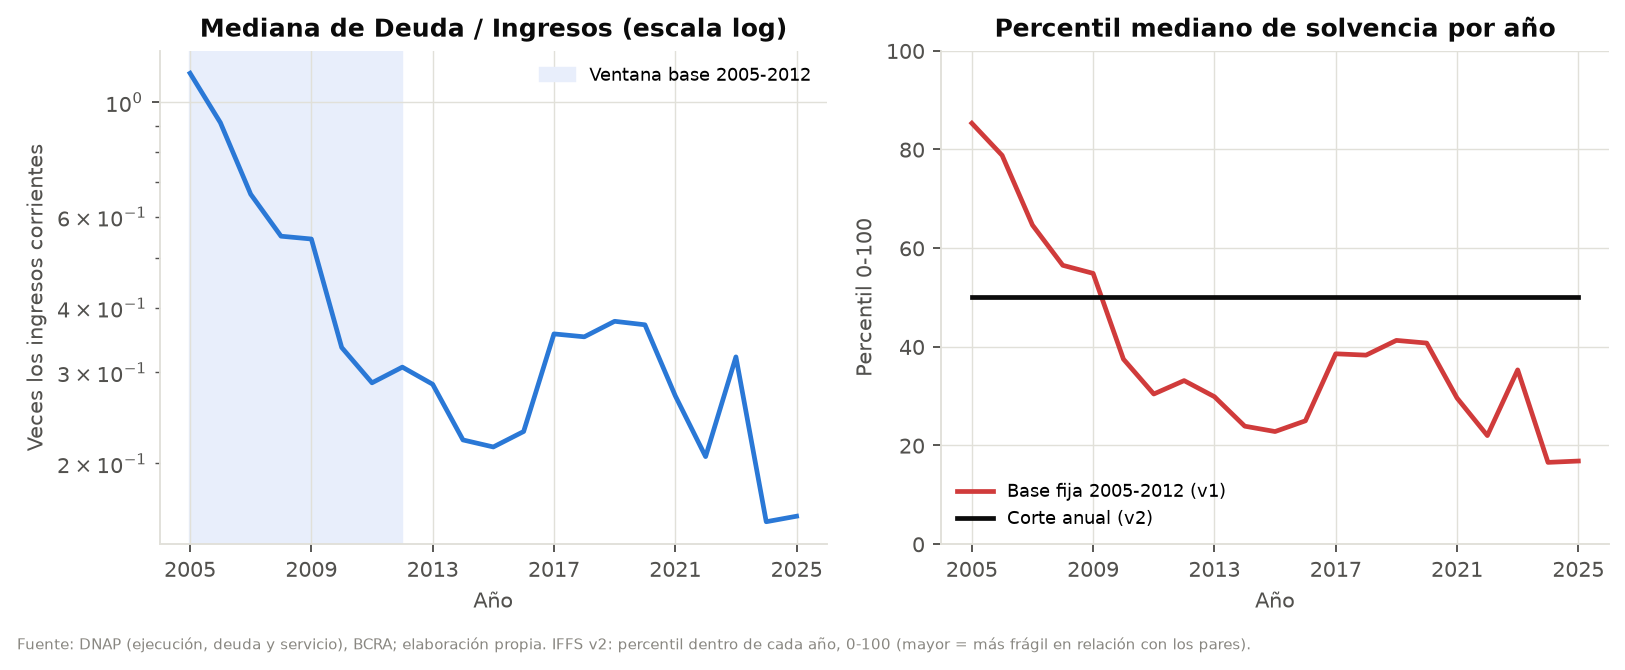

,especificacion,n_obs,spearman_vs_principal,deriva_mediana_anual,persistencia_rangos,cambio_rango_medio
0,PRINCIPAL: corte anual · media simple de solve...,490,"1,000","8,333","0,944","0,000"
1,Normalización: base fija 2005-2012 (legado),490,"0,918","28,801","0,947","0,931"
2,Normalización: base fija 2005-2019,490,"0,923","25,958","0,950","0,849"
3,Normalización: ventana móvil 8 años (sin mirar...,398,"0,934","26,031","0,953","1,015"
4,Normalización: ventana móvil 5 años,421,"0,942","29,300","0,952","0,995"
5,Normalización: pooled todos los años,490,"0,924","25,018","0,948","0,853"
6,Normalización: z-score base 2005-2012,490,"0,906","31,256","0,936","1,304"
7,"Normalización: z-score robusto (mediana/MAD, r...",490,"0,913","28,569","0,940","1,265"


,normalizacion,tratamiento_vs_excluir,cambio_medio_abs_subindice_solvencia_resto,cambio_max_abs,spearman_solvencia_resto
0,corte_anual,supuesto_miles,"2,005","4,076","1,000"
1,corte_anual,sin_tratar,"2,083","4,076","1,000"
2,base_fija,supuesto_miles,"2,059","3,397","1,000"
3,base_fija,sin_tratar,"1,750","4,167","1,000"
4,zscore_base,supuesto_miles,"1,408","1,863","1,000"
5,zscore_base,sin_tratar,"21,541","54,031","1,000"
6,zscore_robusto_base,supuesto_miles,"1,111","1,442","1,000"
7,zscore_robusto_base,sin_tratar,"1,890","2,927","1,000"


In [11]:
fig("deriva_normalizacion", 900)
spec = tabla("T05_comparacion_especificaciones")
display(spec[spec.especificacion.str.contains("PRINCIPAL|Normalización")][["especificacion", "n_obs", "spearman_vs_principal", "deriva_mediana_anual", "persistencia_rangos", "cambio_rango_medio"]])
display(tabla("T17_sensibilidad_la_pampa"))

In [12]:
d = R["deriva_solvencia"]
r = R["robustez_diseno"]
display(Markdown(
    f"**[EVIDENCIA]** La mediana de Deuda/Ingresos cae de {d['mediana_2005']} (2005) a {d['mediana_2012']} (2012) y {d['mediana_2024']} (2024): la ventana 2005-2012 **no es estacionaria** (el desendeudamiento ocurre *dentro* de la propia base). "
    f"Contra esa base, el percentil mediano del compuesto se desplaza {r['Normalización: base fija 2005-2012 (legado)']['deriva_mediana']} puntos a lo largo de los años; con el corte anual, {R['robustez_diseno']['PRINCIPAL: corte anual · media simple de solvencia, liquidez y estructural']['deriva_mediana']}. "
    f"Un error de unidades como el de La Pampa sin tratar mueve el subíndice de solvencia del resto {R['la_pampa']['efecto_sobre_resto']['corte_anual|sin_tratar']} puntos con percentiles y {R['la_pampa']['efecto_sobre_resto']['zscore_base|sin_tratar']} con z-score.\n\n"
    "**[DISEÑO] Decisión: percentil dentro de cada año.** Responde \"¿qué tan frágil es la provincia respecto de sus pares *ese año*?\", no usa información futura y es inmune a la magnitud de un outlier. "
    "**[LIMITACIÓN]** Si todas las provincias mejoran o empeoran a la vez, el score no lo muestra: por eso el dashboard muestra siempre el **nivel común** (mediana de cada razón por año). "
    "La \"posición\" es el **cuartil del compuesto dentro de cada año**; reemplaza a los cortes 33/66/85 del v1, que eran arbitrarios y estaban anclados a 2005-2012."))

**[EVIDENCIA]** La mediana de Deuda/Ingresos cae de 1,14 (2005) a 0,31 (2012) y 0,15 (2024): la ventana 2005-2012 **no es estacionaria** (el desendeudamiento ocurre *dentro* de la propia base). Contra esa base, el percentil mediano del compuesto se desplaza 28,8 puntos a lo largo de los años; con el corte anual, 8.3. Un error de unidades como el de La Pampa sin tratar mueve el subíndice de solvencia del resto 2,08 puntos con percentiles y 21,54 con z-score.

**[DISEÑO] Decisión: percentil dentro de cada año.** Responde "¿qué tan frágil es la provincia respecto de sus pares *ese año*?", no usa información futura y es inmune a la magnitud de un outlier. **[LIMITACIÓN]** Si todas las provincias mejoran o empeoran a la vez, el score no lo muestra: por eso el dashboard muestra siempre el **nivel común** (mediana de cada razón por año). La "posición" es el **cuartil del compuesto dentro de cada año**; reemplaza a los cortes 33/66/85 del v1, que eran arbitrarios y estaban anclados a 2005-2012.

## 6. Construcción del IFFS v2

In [13]:
print("Especificación principal:", ind.ESPEC_PRINCIPAL)
cols = ["provincia", "anio", "S_solvencia", "S_liquidez", "S_estructural", "S_coyuntural", "IFFS", "posicion"]
display(panel[panel.anio == 2024].sort_values("IFFS", ascending=False)[cols].round(1).reset_index(drop=True).head(24))
print()
print(panel[ind.COLS_S + ["IFFS"]].describe().round(1))

Especificación principal: Especificacion(nombre='IFFS v2 (principal)', normalizacion='corte_anual', base_window=(2005, 2012), ventana_movil=8, min_hist_movil=4, suavizado_liquidez=1, suavizado_resultado=1, agregacion='media', dims_compuesto=('solvencia', 'liquidez', 'estructural'), pesos=(), winsor=None)


,provincia,anio,S_solvencia,S_liquidez,S_estructural,S_coyuntural,IFFS,posicion
0,Chubut,2024,"89,600","81,200","81,200","35,400","84,000",Cuartil 4 (mayor fragilidad relativa)
1,Río Negro,2024,"64,600","89,600","97,900","77,100","84,000",Cuartil 4 (mayor fragilidad relativa)
2,Jujuy,2024,"85,400","85,400","77,100","6,200","82,600",Cuartil 4 (mayor fragilidad relativa)
3,Salta,2024,"60,400","93,800","93,800","56,200","82,600",Cuartil 4 (mayor fragilidad relativa)
4,Neuquén,2024,"68,800","72,900","68,800","22,900","70,100",Cuartil 4 (mayor fragilidad relativa)
5,Buenos Aires,2024,"97,900","77,100","22,900","93,800","66,000",Cuartil 4 (mayor fragilidad relativa)
6,La Rioja,2024,"93,800","35,400","64,600","43,800","64,600",Cuartil 3
7,Entre Ríos,2024,"72,900","60,400","52,100","81,200","61,800",Cuartil 3
8,Chaco,2024,"56,200","68,800","56,200","97,900","60,400",Cuartil 3
9,Tucumán,2024,"35,400","56,200","89,600","18,800","60,400",Cuartil 3



       S_solvencia  S_liquidez  S_estructural  S_coyuntural    IFFS
count      490,000     503,000        503,000       503,000 490,000
mean        50,000      50,000         50,000        50,000  50,500
std         28,900      28,900         28,900        28,900  23,800
min          2,100       2,100          2,100         2,100   2,100
25%         23,900      25,500         25,500        25,500  33,000
50%         50,000      50,000         50,000        50,000  51,500
75%         76,100      74,500         74,500        74,500  68,800
max         97,900      97,900         97,900        97,900  97,900


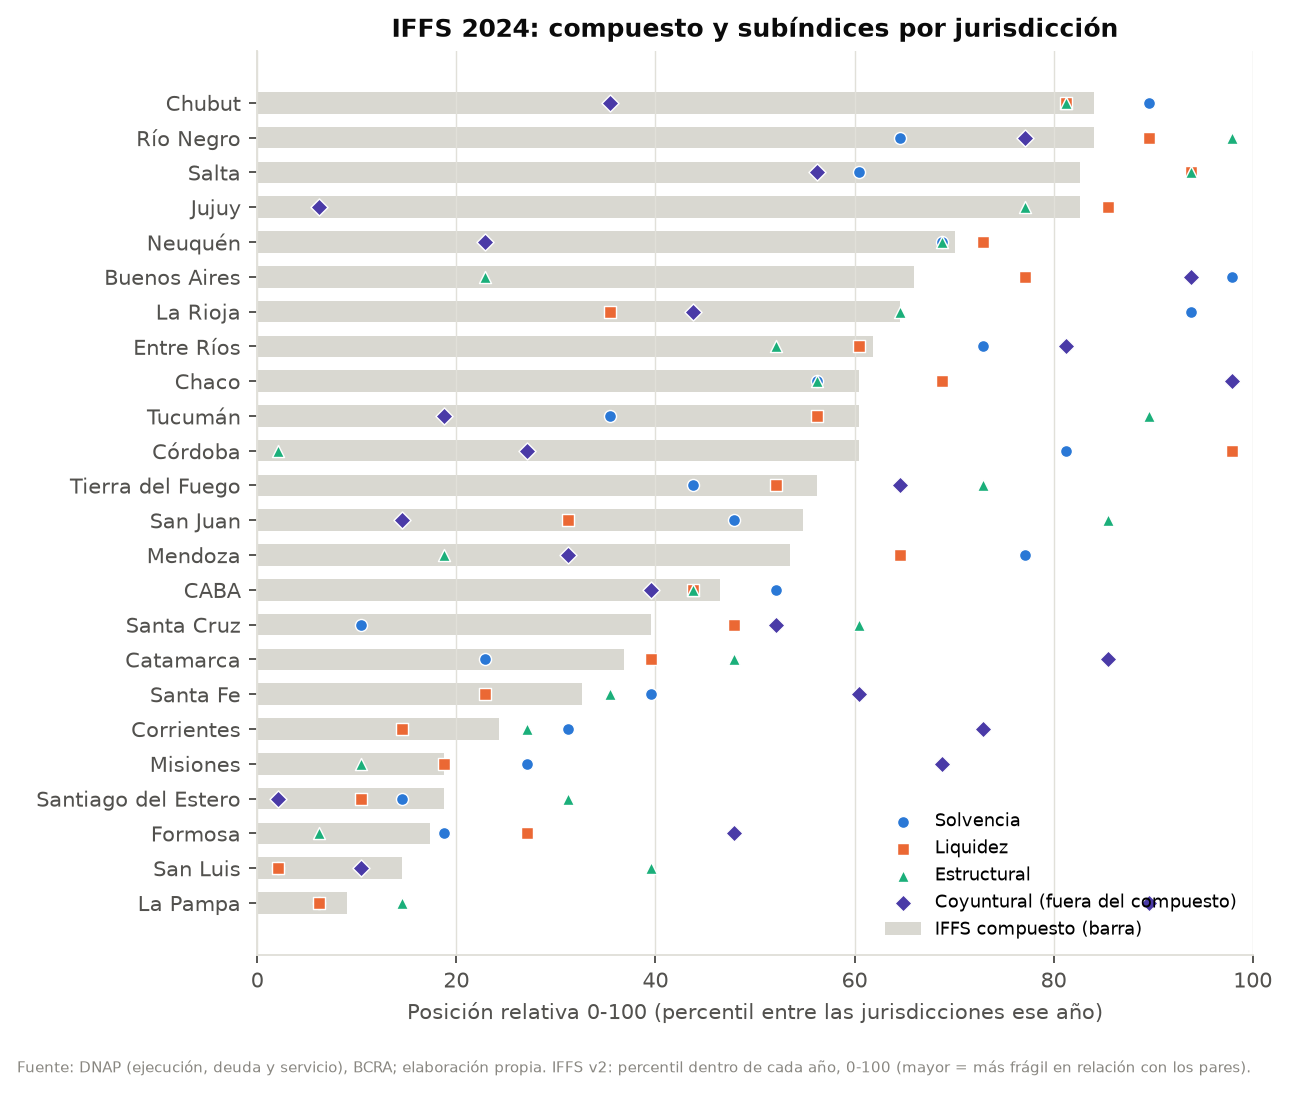

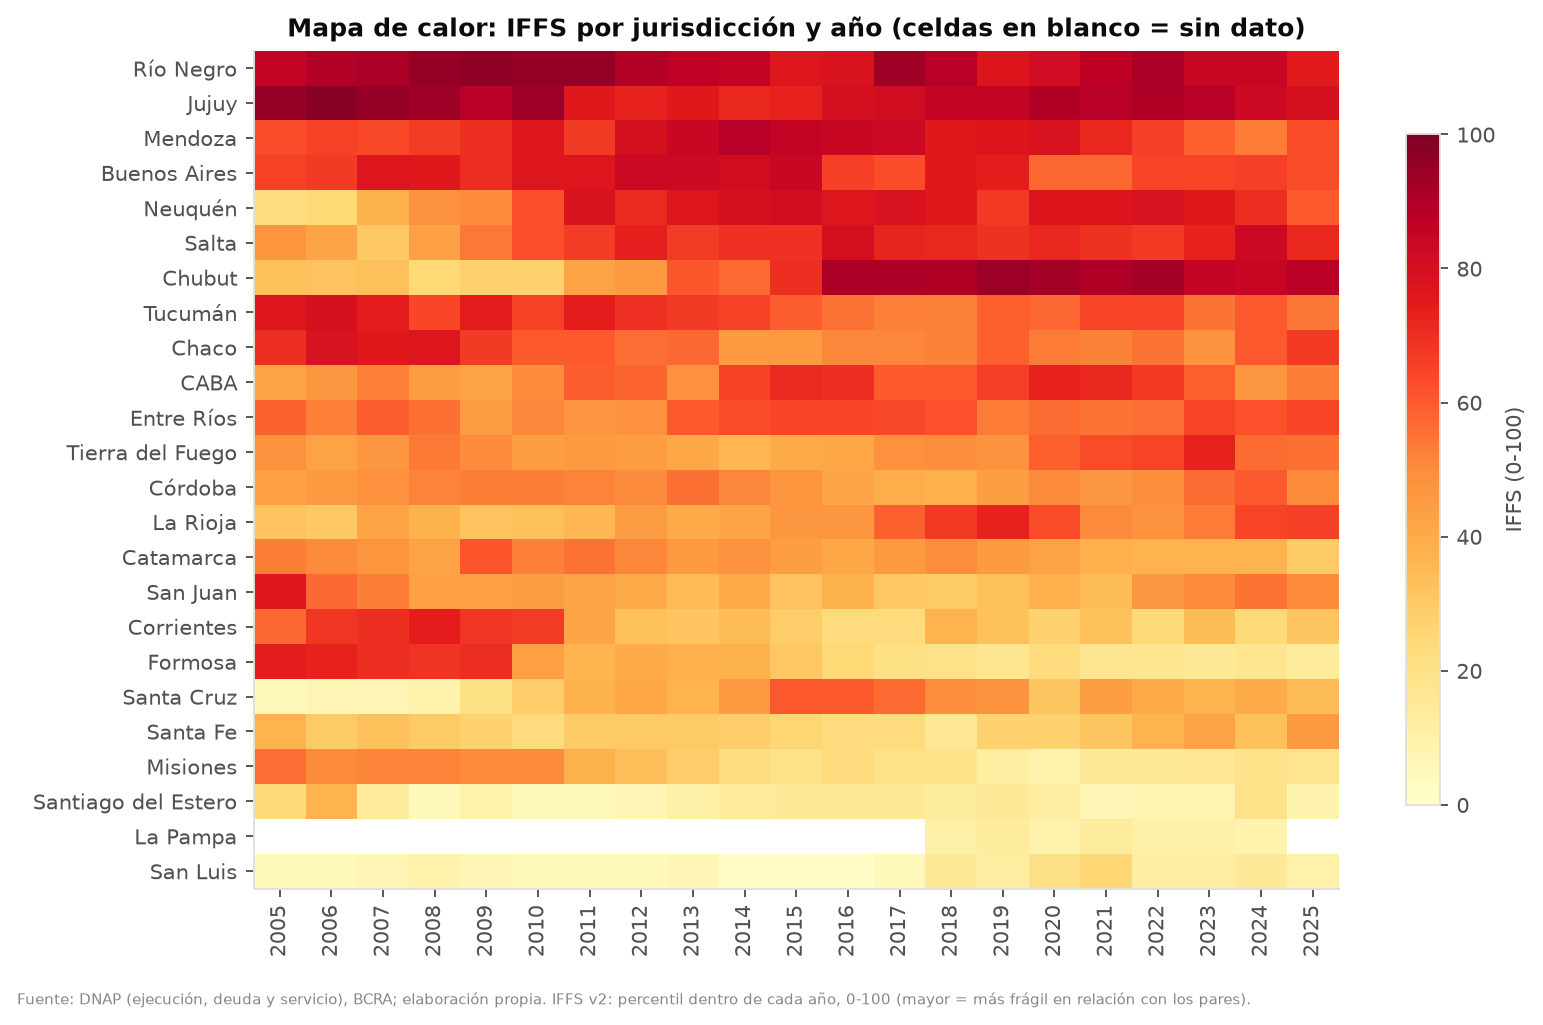

In [14]:
fig("ranking_iffs_2024", 760)
fig("heatmap_IFFS", 900)

In [15]:
display(Markdown("**Nivel común** (mediana de las 24 jurisdicciones): lo que un score relativo no puede mostrar."))
nc = pd.read_csv(TAB / "T15_nivel_comun.csv", index_col=0)
fig_nc, axes = plt.subplots(1, 4, figsize=(12, 2.8))
for ax, col in zip(axes, nc.columns):
    ax.plot(nc.index, nc[col], color="#2a78d6", lw=2)
    ax.set_title(col, fontsize=9)
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

**Nivel común** (mediana de las 24 jurisdicciones): lo que un score relativo no puede mostrar.

## 7. Robustez del diseño (sin usar eventos)
Cada decisión se cambia **una a la vez** y se mide cuánto cambia el ordenamiento (correlación de Spearman con el principal, cambio medio de puesto, cuántas observaciones cambian ≥ 5 puestos).

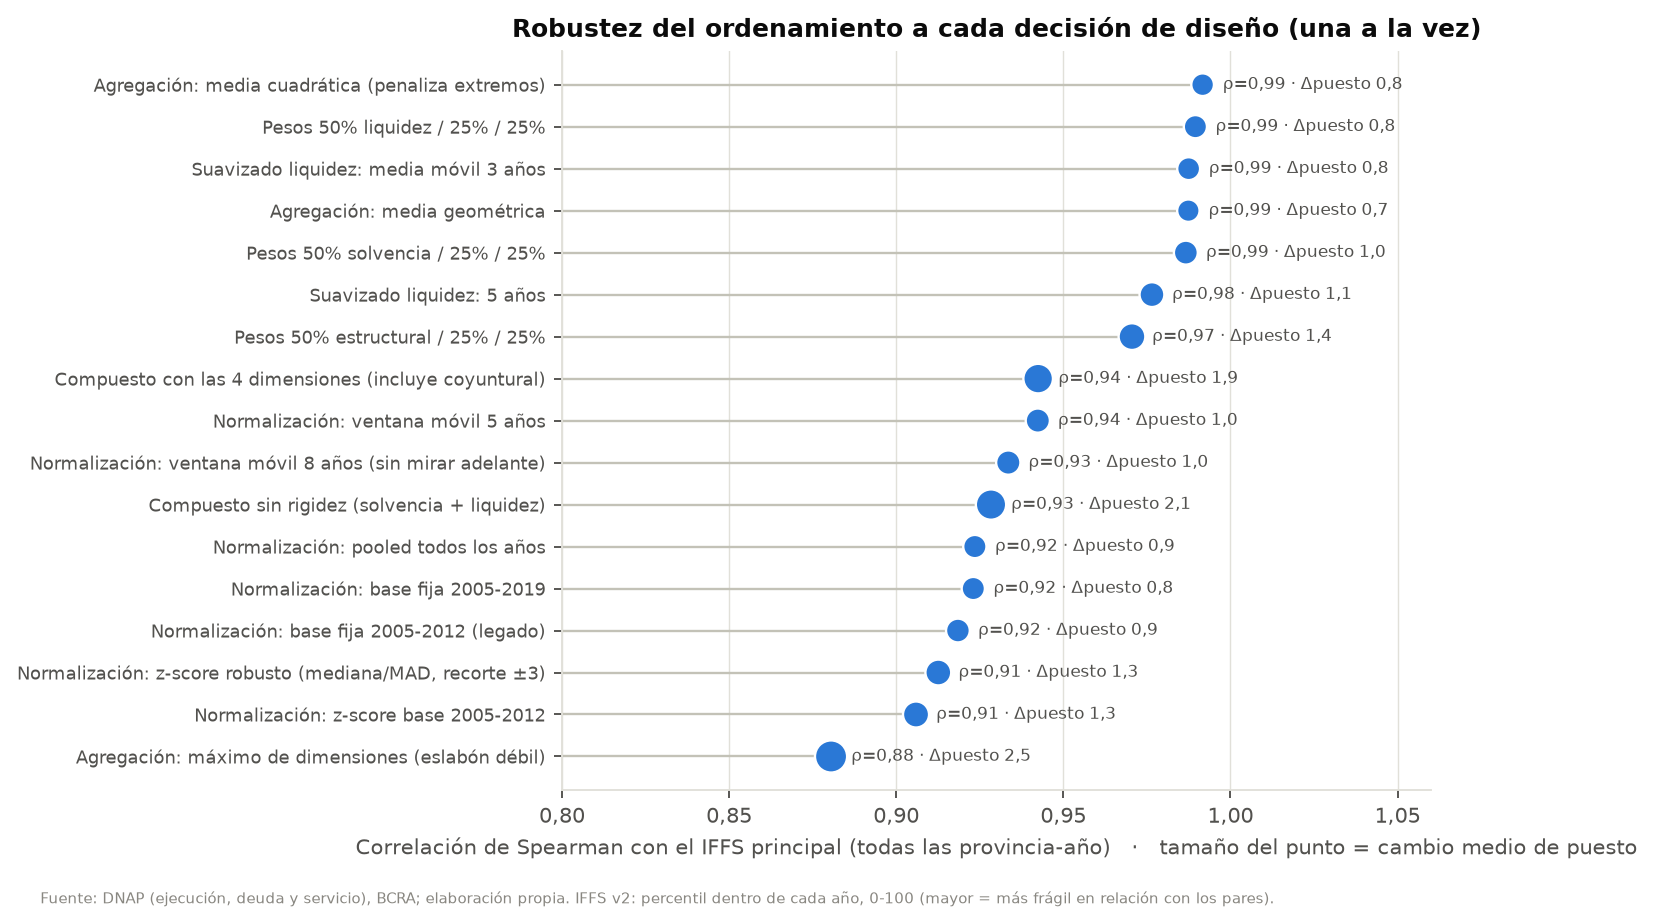

,especificacion,n_obs,spearman_vs_principal,deriva_mediana_anual,persistencia_rangos,cambio_rango_medio,obs_con_cambio_rango_ge5,solapamiento_top6_2024
0,PRINCIPAL: corte anual · media simple de solve...,490,"1,000","8,333","0,944","0,000",0,6
1,Normalización: base fija 2005-2012 (legado),490,"0,918","28,801","0,947","0,931",5,6
2,Normalización: base fija 2005-2019,490,"0,923","25,958","0,950","0,849",2,5
3,Normalización: ventana móvil 8 años (sin mirar...,398,"0,934","26,031","0,953","1,015",6,6
4,Normalización: ventana móvil 5 años,421,"0,942","29,300","0,952","0,995",6,6
5,Normalización: pooled todos los años,490,"0,924","25,018","0,948","0,853",2,6
6,Normalización: z-score base 2005-2012,490,"0,906","31,256","0,936","1,304",17,5
7,"Normalización: z-score robusto (mediana/MAD, r...",490,"0,913","28,569","0,940","1,265",16,5
8,Suavizado liquidez: media móvil 3 años,490,"0,987","10,115","0,962","0,798",9,5
9,Suavizado liquidez: 5 años,490,"0,977","9,903","0,966","1,100",18,5


**Pesos aleatorios** (2,000 vectores uniformes en el simplex sobre las 3 dimensiones): correlación media con el ordenamiento de pesos iguales, mediana 0,94 (percentil 5: 0,80, mínimo 0,70); el 65% de las 126 observaciones del cuartil superior sigue ahí en ≥ 80% de los sorteos.

In [16]:
fig("robustez_especificaciones", 900)
display(tabla("T05_comparacion_especificaciones").round(3))
w = R["pesos_aleatorios"]
display(Markdown(f"**Pesos aleatorios** ({w['n_sim']:,} vectores uniformes en el simplex sobre las 3 dimensiones): correlación media con el ordenamiento de pesos iguales, mediana {c(w['spearman_medio_mediana'])} "
                 f"(percentil 5: {c(w['spearman_medio_p05'])}, mínimo {c(w['spearman_medio_min'])}); el {100*w['cuartil_superior_estable_ge80']:.0f}% de las {w['n_obs_cuartil_superior']} observaciones del cuartil superior sigue ahí en ≥ 80% de los sorteos."))

**Lectura.**
- **[EVIDENCIA]** El ordenamiento es robusto a normalización, ventana, pesos y agregación (ρ entre 0,88 y 0,99 con el principal). La alternativa más distinta es el "eslabón débil" (máximo de las dimensiones).
- **[EVIDENCIA]** Los puestos individuales sí se mueven: hay observaciones que cambian ≥ 5 puestos según la especificación. **[INTERPRETACIÓN]** No conviene leer diferencias de 1-2 puestos como fragilidad distinta.
- Incluir el subíndice coyuntural en el compuesto reduce la persistencia del ordenamiento (0,89 vs. 0,94): consistente con dejarlo aparte.

In [17]:
rk = tabla("T14_ranking_comparado")
display(rk[rk.anio == 2024].drop(columns="anio").reset_index(drop=True))
print("Puestos de 2024 (1 = más frágil) bajo cinco especificaciones: los cambios de ranking son de pocos puestos, salvo casos puntuales.")

,provincia,principal,base_fija_2005_12 (v1),ventana_movil_8a,zscore_robusto,4_dimensiones
0,Chubut,"1,000","2,000","3,000","4,000","4,000"
1,Río Negro,"1,000","4,000","1,000","1,000","1,000"
2,Jujuy,"3,000","1,000","2,000","2,000","7,000"
3,Salta,"3,000","3,000","4,000","3,000","2,000"
4,Neuquén,"5,000","5,000","5,000","5,000","9,000"
5,Buenos Aires,"6,000","6,000","6,000","9,000","3,000"
6,La Rioja,"7,000","7,000","7,000","7,000","8,000"
7,Entre Ríos,"8,000","9,000","8,000","10,000","6,000"
8,Chaco,"9,000","8,000","9,000","8,000","5,000"
9,Córdoba,"10,000","14,000","14,000","14,000","11,000"


Puestos de 2024 (1 = más frágil) bajo cinco especificaciones: los cambios de ranking son de pocos puestos, salvo casos puntuales.


## 8. Validación con eventos: descripción, discriminación y anticipación

Son **tres preguntas distintas** y ninguna implica a la siguiente:
- **Descripción:** ¿qué muestra el índice? (§6-7)
- **Discriminación:** en una fecha, ¿las provincias que luego reestructuraron tenían un score más alto? *(AUC, IC bootstrap, permutación)*
- **Anticipación:** ¿el score *subió* antes del evento más que en las demás? *(pretendencia, estudio de eventos, placebo temporal)*

### 8.1 Los eventos y por qué no hay un modelo predictivo

In [18]:
ev = tabla("T18_eventos")[["provincia", "anio_evento", "tipo_evento", "fecha_puntual", "anio_ancla_alt", "bloque"]]
display(ev)
e = R["eventos"]
display(Markdown(f"**[EVIDENCIA]** {e['n_eventos']} eventos sobre {R['cobertura']['n_total']} provincia-año ({e['tasa_base_pct']}%); {e['n_covid']} en el bloque 2020-21 y 1 en 2025 (La Rioja). "
                 f"**[SUPUESTO]** Para {e['n_anio_ambiguo']} de los {e['n_covid']} del bloque 2020-21 la fuente dice \"2020-2021\" sin año por provincia: el año 2020 es **mi convención**; todo el análisis de *timing* se repite con ancla 2021. "
                 "Además, los 12 eventos son esencialmente **un** shock común observado en 12 unidades, no 12 observaciones independientes."))
sp = R["split_temporal"]
print("Intento de split temporal (entrenar ≤ 2019, evaluar > 2019):", {k: sp[k] for k in ["obs_entrenamiento", "eventos_entrenamiento", "obs_evaluacion", "eventos_evaluacion", "viable"]})
display(tabla("T13_pruebas_no_viables"))

,provincia,anio_evento,tipo_evento,fecha_puntual,anio_ancla_alt,bloque
0,La Rioja,2020,Default / reestructuración de deuda,True,2020,COVID 2020-21
1,Mendoza,2020,Reestructuración de bonos internacionales,False,2021,COVID 2020-21
2,Neuquén,2020,Reestructuración de bonos internacionales,False,2021,COVID 2020-21
3,Córdoba,2020,Reestructuración de bonos internacionales,False,2021,COVID 2020-21
4,Chubut,2020,Reestructuración de bonos internacionales,False,2021,COVID 2020-21
5,Río Negro,2020,Reestructuración de bonos internacionales,False,2021,COVID 2020-21
6,Salta,2020,Reestructuración de bonos internacionales,False,2021,COVID 2020-21
7,Entre Ríos,2020,Reestructuración de bonos internacionales,False,2021,COVID 2020-21
8,Jujuy,2020,Reestructuración de bonos internacionales,False,2021,COVID 2020-21
9,Chaco,2020,Reestructuración de bonos internacionales,False,2021,COVID 2020-21


**[EVIDENCIA]** 13 eventos sobre 504 provincia-año (2,6%); 12 en el bloque 2020-21 y 1 en 2025 (La Rioja). **[SUPUESTO]** Para 11 de los 12 del bloque 2020-21 la fuente dice "2020-2021" sin año por provincia: el año 2020 es **mi convención**; todo el análisis de *timing* se repite con ancla 2021. Además, los 12 eventos son esencialmente **un** shock común observado en 12 unidades, no 12 observaciones independientes.

Intento de split temporal (entrenar ≤ 2019, evaluar > 2019): {'obs_entrenamiento': 360, 'eventos_entrenamiento': 0, 'obs_evaluacion': 144, 'eventos_evaluacion': 13, 'viable': False}


,prueba,por_que_no_es_viable
0,Modelo supervisado con corte temporal (entrena...,0 eventos antes de 2020: no hay ninguna observ...
1,Probabilidad de default calibrada (logit/probi...,13 eventos sobre 504 observaciones provincia-a...
2,Optimización de pesos o umbrales para maximiza...,Con 13 eventos (12 simultáneos) cualquier opti...
3,Modelo de duración / riesgo proporcional (Cox),Los 12 eventos del bloque COVID comparten fech...
4,Estudio de eventos con efectos de tratamiento ...,Requiere cohortes de adopción en años distinto...
5,Estimación del año exacto de cada evento (timing),"De los 12 eventos del bloque 2020-21, solo 1 t..."
6,Validación fuera de muestra con el evento de L...,Es UNA observación: sirve para mostrar la tray...
7,Comparación con calificaciones crediticias,No hay una base pública gratuita y consistente...


### 8.2 Discriminación en 2019 (T−1 del ancla 2020)

In [19]:
disc = tabla("T07_discriminacion_2019")
display(disc.round(4))
d = R["discriminacion_2019"]; z = R["azar_auc_2019"]; b = R["condicionado_a_bonos_2019"]
display(Markdown(
    f"**[EVIDENCIA]** El IFFS compuesto tiene AUC **{c(d['IFFS compuesto (principal)']['auc'])}** [IC 95%: {c(d['IFFS compuesto (principal)']['ic95'][0])}–{c(d['IFFS compuesto (principal)']['ic95'][1])}]: en 2019, una provincia con evento tenía un score mayor que una sin evento el 93% de las veces. "
    f"Si los 12 'eventos' fueran un sorteo al azar, el AUC superaría {c(z['azar_p95'])} solo el 5% de las veces. Por subíndice: solvencia {c(d['Subíndice solvencia']['auc'])}, liquidez {c(d['Subíndice liquidez']['auc'])}, "
    f"estructural {c(d['Subíndice estructural']['auc'])}, coyuntural {c(d['Subíndice coyuntural']['auc'])} (IC que incluye 0,5 en los dos últimos casos: apenas hay señal).\n\n"
    f"**Pero:** una variable trivial, la **participación de bonos en la deuda**, alcanza AUC {c(d['Benchmark: participación de bonos en la deuda (%)']['auc'])} [{c(d['Benchmark: participación de bonos en la deuda (%)']['ic95'][0])}–{c(d['Benchmark: participación de bonos en la deuda (%)']['ic95'][1])}]. "
    "**[INTERPRETACIÓN]** Solo las provincias con bonos de mercado podían reestructurar bonos: parte de lo que el índice 'discrimina' es acceso al mercado. "
    f"Entre las {b['n_emisoras']} emisoras (≥ {b['min_bonos_pct']:.0f}% de bonos), el AUC del compuesto es {c(b['auc_IFFS'])}, pero con solo {b['n_control']} controles ({', '.join(b['controles'])}) **no hay poder estadístico** para concluir algo."))

,medida,anio_ref,auc,ic95_inf,ic95_sup,p_perm_unilateral,n_evento,n_control
0,IFFS compuesto (principal),2019,"0,931","0,805","1,000","0,000",12,12
1,Subíndice solvencia,2019,"0,972","0,889","1,000","0,000",12,12
2,Subíndice liquidez,2019,"0,910","0,743","1,000","0,000",12,12
3,Subíndice estructural,2019,"0,722","0,472","0,931","0,033",12,12
4,Subíndice coyuntural,2019,"0,681","0,444","0,889","0,075",12,12
5,"IFFS legado B (base fija 2005-12, 4 dims)",2019,"0,931","0,799","1,000","0,000",12,12
6,Benchmark: participación de bonos en la deuda (%),2019,"0,868","0,681","1,000","0,001",12,12
7,Benchmark: dependencia de transferencias,2019,"0,396","0,160","0,653","0,808",12,12


**[EVIDENCIA]** El IFFS compuesto tiene AUC **0,93** [IC 95%: 0,81–1,00]: en 2019, una provincia con evento tenía un score mayor que una sin evento el 93% de las veces. Si los 12 'eventos' fueran un sorteo al azar, el AUC superaría 0,70 solo el 5% de las veces. Por subíndice: solvencia 0,97, liquidez 0,91, estructural 0,72, coyuntural 0,68 (IC que incluye 0,5 en los dos últimos casos: apenas hay señal).

**Pero:** una variable trivial, la **participación de bonos en la deuda**, alcanza AUC 0,87 [0,68–1,00]. **[INTERPRETACIÓN]** Solo las provincias con bonos de mercado podían reestructurar bonos: parte de lo que el índice 'discrimina' es acceso al mercado. Entre las 14 emisoras (≥ 25% de bonos), el AUC del compuesto es 0,88, pero con solo 3 controles (CABA, Misiones, Santa Fe) **no hay poder estadístico** para concluir algo.

### 8.3 Rezagos T−1 … T−5 y sensibilidad al año ancla

In [20]:
rez = tabla("T08_discriminacion_por_rezago")
rz = rez[rez.medida.isin(["IFFS", "solvencia", "liquidez", "bonos_pct", "IFFS_v1"])].copy()
rz["AUC [IC95%]"] = rz.apply(lambda r: es(f"{r['auc']:.2f} [{r['ic95_inf']:.2f}–{r['ic95_sup']:.2f}]"), axis=1)
display(rz.pivot_table(index=["ancla", "medida"], columns="rezago", values="AUC [IC95%]", aggfunc="first"))
print("Ancla 2020 = convención; ancla alternativa = 2021 para los eventos de fecha ambigua.")

rezago                                                      1                 2                 3                 4                 5
ancla                             medida                                                                                             
2020 (convención)                 IFFS       0,93 [0,81–1,00]  0,94 [0,83–1,00]  0,92 [0,77–1,00]  0,89 [0,73–1,00]  0,88 [0,70–0,98]
                                  IFFS_v1    0,93 [0,80–1,00]  0,97 [0,89–1,00]  0,93 [0,79–1,00]  0,85 [0,65–0,99]  0,86 [0,67–0,99]
                                  bonos_pct  0,87 [0,68–1,00]  0,86 [0,67–1,00]  0,85 [0,65–1,00]  0,71 [0,47–0,90]  0,74 [0,51–0,92]
                                  liquidez   0,91 [0,74–1,00]  0,92 [0,78–1,00]  0,93 [0,79–1,00]  0,87 [0,67–1,00]  0,84 [0,64–0,99]
                                  solvencia  0,97 [0,89–1,00]  0,98 [0,92–1,00]  0,94 [0,81–1,00]  0,86 [0,68–0,98]  0,80 [0,59–0,95]
2021 para los 11 de fecha ambigua IFFS       0,93 [0,80–1,00]  0,93 [0,81–1,00]  0,94 [0,81–1,00]  0,90 [0,73–0,99]  0,89 [0,73–1,00]
                                  IFFS_v1    0,90 [0,74–1,00]  0,93 [0,80–1,00]  0,97 [0,89–1,00]  0,92 [0,78–1,00]  0,85 [0,65–0,99]
                                  bonos_pct  0,91 [0,76–1,00]  0,87 [0,68–1,00]  0,86 [0,67–1,00]  0,83 [0,61–0,99]  0,72 [0,48–0,91]
                                  liquidez   0,92 [0,75–1,00]  0,90 [0,72–1,00]  0,92 [0,78–1,00]  0,92 [0,78–1,00]  0,88 [0,68–1,00]
                                  solvencia  0,97 [0,89–1,00]  0,97 [0,89–1,00]  0,98 [0,92–1,00]  0,90 [0,75–1,00]  0,86 [0,68–0,98]

Ancla 2020 = convención; ancla alternativa = 2021 para los eventos de fecha ambigua.


**Lectura [EVIDENCIA].** El AUC del compuesto se mantiene alto de T−1 a T−5 (≈ 0,88-0,94) con cualquiera de los dos anclajes: no depende de mi convención sobre el año. **[LIMITACIÓN]** Un AUC alto con rezago largo dice que el grupo *ya era* más frágil,
no que el score alerte antes de un deterioro; eso se evalúa en las secciones siguientes.

### 8.4 Placebo temporal: ¿cuándo aparece la separación?
Se calcula el AUC de **las mismas 12 provincias** contra las demás en **todos** los años (antes y después de los eventos). Si el grupo ya estaba separado años antes, el nivel más alto es un rasgo persistente, no una señal que aparezca antes del shock.

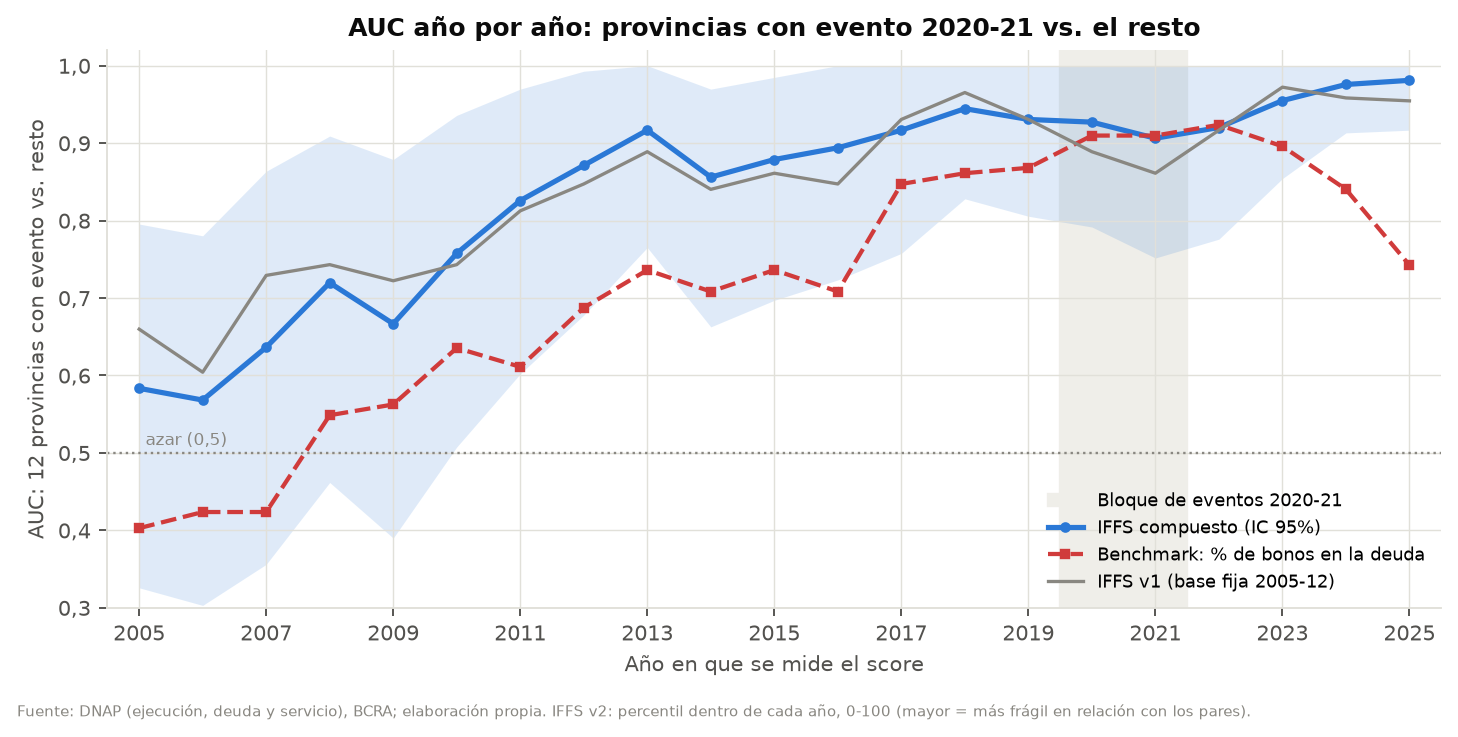

**[EVIDENCIA]** El AUC del IFFS es 0,583 en 2005, 0,871 en 2012 (primer año con AUC ≥ 0,85: 2012), 0,931 en 2019 y **0,981 en 2025, después de los eventos**. El IC 95% deja de incluir 0,5 desde 2010. **[INTERPRETACIÓN]** El grupo que reestructuró en 2020-21 es más frágil desde hace más de una década y lo sigue siendo: el índice **discrimina un rasgo persistente**; no hay evidencia de que "encienda una alarma" antes del shock.

In [21]:
fig("auc_por_anio", 900)
pv = R["placebo_temporal"]
display(Markdown(f"**[EVIDENCIA]** El AUC del IFFS es {pv['auc_iffs_por_anio']['2005']} en 2005, {pv['auc_iffs_por_anio']['2012']} en 2012 (primer año con AUC ≥ 0,85: {pv['primer_anio_auc_ge_085']}), {pv['auc_iffs_por_anio']['2019']} en 2019 y "
                 f"**{pv['auc_iffs_por_anio']['2025']} en 2025, después de los eventos**. El IC 95% deja de incluir 0,5 desde {pv['primer_anio_ic_sobre_azar']}. "
                 "**[INTERPRETACIÓN]** El grupo que reestructuró en 2020-21 es más frágil desde hace más de una década y lo sigue siendo: el índice **discrimina un rasgo persistente**; no hay evidencia de que \"encienda una alarma\" antes del shock."))

### 8.5 Anticipación: pretendencia y estudio de eventos
**Pretendencia:** cambio del score entre T−5 y T−1, provincias con evento vs. resto (diferencia de medias de los cambios, IC 95% bootstrap, permutación bilateral).

,col,desde,hasta,cambio_medio_evento,cambio_medio_control,diferencia,ic95_inf,ic95_sup,p_perm_bilateral
0,IFFS,T-5,T-1,"3,160","-2,000","5,160","-2,570","13,520","0,280"
1,IFFS,T-3,T-1,"-0,180","1,390","-1,570","-7,590","4,660","0,640"
2,S_solvencia,T-5,T-1,"9,480","-6,370","15,850","0,380","33,330","0,080"
3,S_solvencia,T-3,T-1,"2,600","1,140","1,450","-8,080","12,310","0,790"
4,S_liquidez,T-5,T-1,"3,470","-3,470","6,940","-9,030","24,310","0,470"
5,S_liquidez,T-3,T-1,"-1,040","1,040","-2,080","-14,930","11,110","0,810"
6,S_estructural,T-5,T-1,"-3,470","3,470","-6,940","-21,180","6,250","0,400"
7,S_estructural,T-3,T-1,"-2,080","2,080","-4,170","-14,930","7,290","0,520"
8,S_coyuntural,T-5,T-1,"0,690","-0,690","1,390","-25,690","27,430","0,940"
9,S_coyuntural,T-3,T-1,"-6,940","6,940","-13,890","-35,430","7,640","0,270"


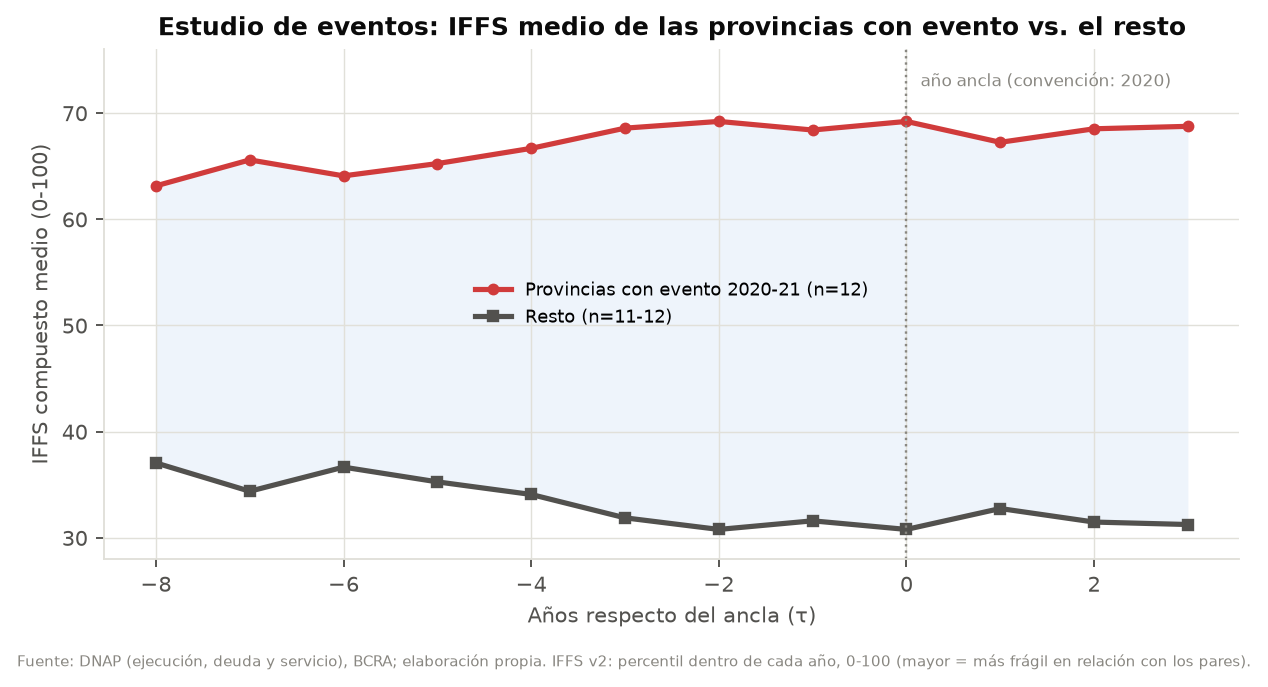

**[EVIDENCIA]** La brecha entre grupos ya es de 26,1 puntos en τ = −8 y de 36,8 en τ = −1. El cambio del compuesto entre T−5 y T−1 fue +3,2 puntos en las provincias con evento y -2,0 en el resto: diferencia +5,2 [-2,6; +13,5], p = 0,28. **No hay evidencia de un deterioro previo distinto en el compuesto.** En solvencia la diferencia es +15,8 [+0,4; +33,3] (el IC bootstrap apenas excluye el cero, pero la permutación da p = 0,08 y es 1 de 10 comparaciones sin corregir): indicio débil, no evidencia. **[LIMITACIÓN]** Con una sola fecha común no hay contrafactual temporal: no se puede separar "ya era más frágil" de "se deterioró antes", y con 12 unidades la potencia es baja (un efecto moderado no se detectaría).

In [22]:
pre = tabla("T10_pretendencia")
pre = pre[pre.ancla == "principal"][["col", "desde", "hasta", "cambio_medio_evento", "cambio_medio_control", "diferencia", "ic95_inf", "ic95_sup", "p_perm_bilateral"]]
display(pre.round(2))
fig("estudio_de_eventos", 720)
e0, e8 = R["estudio_eventos"]["-1"], R["estudio_eventos"]["-8"]
p5 = R["pretendencia"]["principal|IFFS|T-5->T-1"]
ps = R["pretendencia"]["principal|S_solvencia|T-5->T-1"]
display(Markdown(f"**[EVIDENCIA]** La brecha entre grupos ya es de {e8['dif']} puntos en τ = −8 y de {e0['dif']} en τ = −1. El cambio del compuesto entre T−5 y T−1 fue {p5['cambio_evento']:+.1f} puntos en las provincias con evento y {p5['cambio_control']:+.1f} en el resto: "
                 f"diferencia {p5['dif']:+.1f} [{p5['ic95'][0]:+.1f}; {p5['ic95'][1]:+.1f}], p = {c(p5['p'])}. **No hay evidencia de un deterioro previo distinto en el compuesto.** "
                 f"En solvencia la diferencia es {ps['dif']:+.1f} [{ps['ic95'][0]:+.1f}; {ps['ic95'][1]:+.1f}] (el IC bootstrap apenas excluye el cero, pero la permutación da p = {c(ps['p'])} y es 1 de 10 comparaciones sin corregir): indicio débil, no evidencia. "
                 "**[LIMITACIÓN]** Con una sola fecha común no hay contrafactual temporal: no se puede separar \"ya era más frágil\" de \"se deterioró antes\", y con 12 unidades la potencia es baja (un efecto moderado no se detectaría)."))

### 8.6 Un caso fuera del bloque COVID: La Rioja 2025

,anio,S_solvencia,S_liquidez,S_estructural,S_coyuntural,IFFS,puesto_compuesto,n_jurisdicciones_con_dato
0,2019,"85,400","60,400","72,900","52,100","72,900",6,24
1,2020,"85,400","56,200","47,900","18,800","63,200",8,24
2,2021,"81,200","52,100","18,800","77,100","50,700",13,24
3,2022,"68,800","39,600","35,400","77,100","47,900",14,24
4,2023,"89,600","43,800","27,100","56,200","53,500",13,24
5,2024,"93,800","35,400","64,600","43,800","64,600",7,24


Es UNA observación: sirve para mostrar la trayectoria, no para estimar aciertos ni errores. En 2024, año previo al incumplimiento (feb-2025), La Rioja estaba en el puesto 7 de 24 con solvencia 93,8 (0-100).


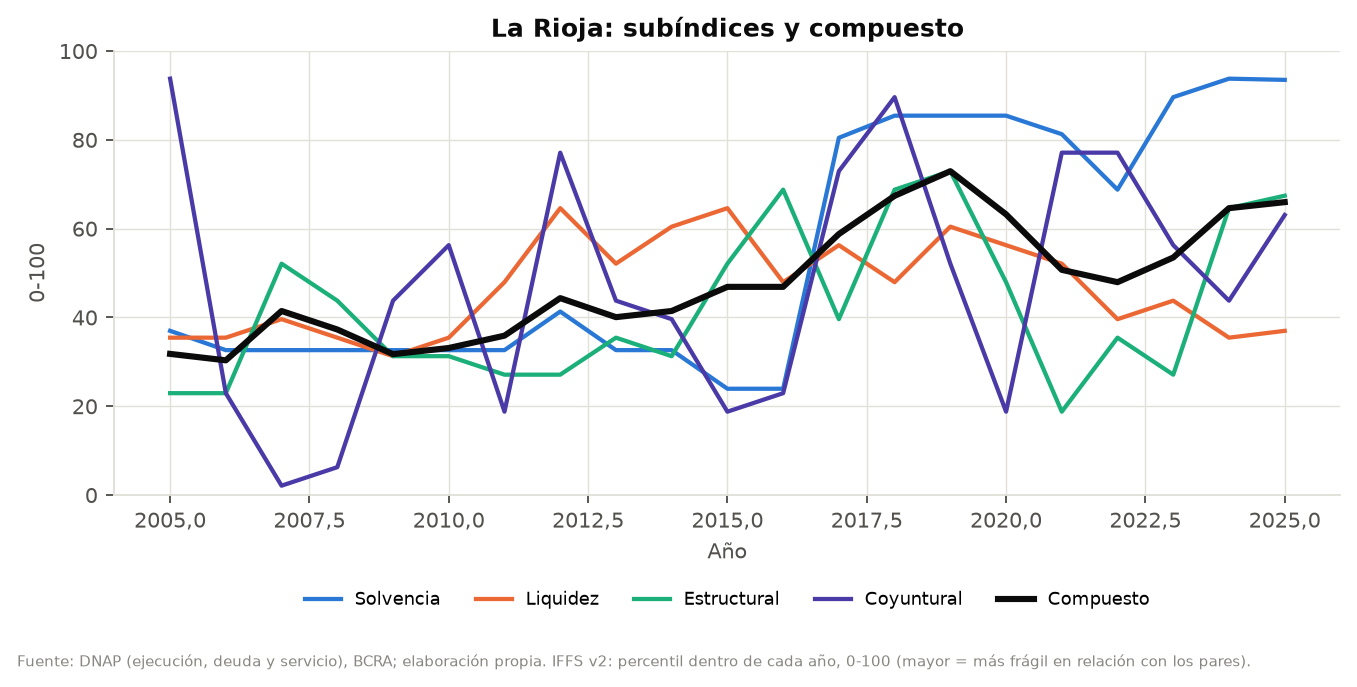

In [23]:
lr = tabla("T12_la_rioja_2025")
display(lr.round(1))
print("Es UNA observación: sirve para mostrar la trayectoria, no para estimar aciertos ni errores. En 2024, año previo al incumplimiento (feb-2025), La Rioja estaba en el puesto",
      R["la_rioja"]["2024"]["puesto"], "de 24 con solvencia", R["la_rioja"]["2024"]["solvencia"], "(0-100).")
fig("subindices_La_Rioja", 720)

### 8.7 ¿Y las otras especificaciones? (todas reportadas)
El AUC de 2019 de cada una de las 18 especificaciones se muestra **sin elegir ninguna**: la especificación principal se fijó por los criterios de diseño (§5), antes de calcular cualquier AUC.

In [24]:
a = tabla("T19_auc_2019_todas_las_especificaciones")
display(a.round(3))
print(f"Rango del AUC 2019 entre las {R['auc_2019_especificaciones']['n']} especificaciones: {R['auc_2019_especificaciones']['min']} – {R['auc_2019_especificaciones']['max']}.")

,especificacion,auc_2019,n_evento,n_control
0,PRINCIPAL,"0,931",12,12
1,Normalización: base fija 2005-2012 (legado),"0,938",12,12
2,Normalización: base fija 2005-2019,"0,944",12,12
3,Normalización: ventana móvil 8 años (sin mirar...,"0,951",12,12
4,Normalización: ventana móvil 5 años,"0,944",12,12
5,Normalización: pooled todos los años,"0,944",12,12
6,Normalización: z-score base 2005-2012,"0,924",12,12
7,"Normalización: z-score robusto (mediana/MAD, r...","0,924",12,12
8,Suavizado liquidez: media móvil 3 años,"0,938",12,12
9,Suavizado liquidez: 5 años,"0,938",12,12


Rango del AUC 2019 entre las 18 especificaciones: 0,819 – 0.951.


## 9. Analítica descriptiva (machine learning clásico, sin costo)
Perfiles, anomalías, un backtest de proyección y un simulador. **Ninguno valida al índice como predictor.** Semilla fija; solo scikit-learn/numpy.

### 9.1 Perfiles fiscales (k-means)

In [25]:
info = T["info_perfiles"]
print(f"k = {info['k']} (elegido por silhouette = {info['silhouette']:.2f}: estructura moderada); silhouettes por k:", {k: round(v, 2) for k, v in info["silhouettes_por_k"].items()})
display(info["centroides"].round(0).rename(index=info["nombres"]))
display(panel[panel.anio == 2024][["provincia", "perfil_nombre", "IFFS"]].sort_values(["perfil_nombre", "IFFS"], ascending=[True, False]).round(1))

k = 5 (elegido por silhouette = 0,30: estructura moderada); silhouettes por k: {3: 0,26, 4: 0,27, 5: 0,3}


,Solvencia,Liquidez,Estructural,Coyuntural
Perfil 1 · Holgado,"15,000","15,000","11,000","58,000"
"Perfil 2 · Intermedio, sin dimensión dominante","45,000","50,000","58,000","15,000"
Perfil 3 · Tensión en estructural y coyuntural,"25,000","37,000","69,000","65,000"
Perfil 4 · Tensión en solvencia y liquidez,"70,000","63,000","24,000","53,000"
Perfil 5 · Tensión generalizada,"82,000","80,000","77,000","67,000"


,provincia,perfil_nombre,IFFS
439,Santa Fe,Perfil 1 · Holgado,"32,600"
124,Corrientes,Perfil 1 · Holgado,"24,300"
292,Misiones,Perfil 1 · Holgado,"18,800"
187,Formosa,Perfil 1 · Holgado,"17,400"
397,San Luis,Perfil 1 · Holgado,"14,600"
229,La Pampa,Perfil 1 · Holgado,"9,000"
208,Jujuy,"Perfil 2 · Intermedio, sin dimensión dominante","82,600"
313,Neuquén,"Perfil 2 · Intermedio, sin dimensión dominante","70,100"
502,Tucumán,"Perfil 2 · Intermedio, sin dimensión dominante","60,400"
376,San Juan,"Perfil 2 · Intermedio, sin dimensión dominante","54,900"


### 9.2 Anomalías (Isolation Forest, descriptivo)

In [26]:
anom = panel[panel.anomalia].sort_values("anomalia_score", ascending=False)[["provincia", "anio", "IFFS", "d_iffs_1a", "anomalia_score"]].round(2)
display(anom)

,provincia,anio,IFFS,d_iffs_1a,anomalia_score
173,Formosa,2010,"43,540","-26,450","0,620"
443,Santiago del Estero,2007,"13,290","-23,670","0,610"
195,Jujuy,2011,"75,660","-18,000","0,610"
395,San Luis,2022,"11,810","-13,890","0,600"
111,Corrientes,2011,"41,610","-25,060","0,590"
95,Chubut,2016,"90,940","21,070","0,590"
442,Santiago del Estero,2006,"36,960","12,440","0,590"
444,Santiago del Estero,2008,"4,890","-8,390","0,590"
461,Santiago del Estero,2025,"7,970","-10,780","0,570"
409,Santa Cruz,2015,"60,210","14,670","0,570"


### 9.3 Proyección exploratoria y backtest honesto

In [27]:
bt = R["backtest_proyeccion"]
display(Markdown(f"En un backtest a 1 año ({bt['n']} casos, sin información futura), extrapolar la tendencia lineal de los últimos 8 años tiene un error absoluto medio de **{bt['mae_tendencia']}** puntos contra **{bt['mae_ingenua']}** de repetir el último valor; "
                 f"la tendencia gana en el {bt['tendencia_gana_pct']:.0f}% de los casos. **[EVIDENCIA]** La proyección **no supera** a la regla ingenua: se informa tal cual y no se presenta como pronóstico."))

En un backtest a 1 año (278 casos, sin información futura), extrapolar la tendencia lineal de los últimos 8 años tiene un error absoluto medio de **6,6** puntos contra **4,6** de repetir el último valor; la tendencia gana en el 29% de los casos. **[EVIDENCIA]** La proyección **no supera** a la regla ingenua: se informa tal cual y no se presenta como pronóstico.

### 9.4 Simulador de escenarios (sensibilidad mecánica)

In [28]:
# Chequeo de consistencia: un escenario nulo debe reproducir exactamente el IFFS observado
difs = []
for prov in panel.provincia.unique():
    r0 = an.simular_escenario(panel, prov, 2023)
    obs = panel[(panel.provincia == prov) & (panel.anio == 2023)]["IFFS"].iloc[0]
    if pd.notna(obs):
        difs.append(abs(r0["iffs_escenario"] - obs))
print(f"Escenario nulo vs. IFFS observado: diferencia máxima = {max(difs):.2e} ({len(difs)} provincias)")
r = an.simular_escenario(panel, "La Rioja", 2024, caida_ingresos=0.10)
print(f"La Rioja 2024 con caída de ingresos del 10%: IFFS {r['iffs_base']:.1f} → {r['iffs_escenario']:.1f} ({r['delta']:+.1f}); posición {r['posicion_base'].split(' (')[0]} → {r['posicion_escenario'].split(' (')[0]}")

Escenario nulo vs. IFFS observado: diferencia máxima = 1,42e-14 (24 provincias)


La Rioja 2024 con caída de ingresos del 10%: IFFS 64,6 → 67,4 (+2,8); posición Cuartil 3 → Cuartil 4


**Lectura.** Es una **sensibilidad mecánica**: los ingresos caen, el gasto se mantiene y las demás jurisdicciones quedan fijas; la depreciación solo afecta a provincias con dato de composición por moneda (11 de 24) y la suba del servicio es una cota superior (incluye capital).
No es un pronóstico.

### 9.5 Cambios de posición y análisis automático

In [29]:
display(an.ranking_cambios(panel, 2025).round(1).head(8))
display(Markdown(an.generar_analisis(panel, "La Rioja", 2024, eventos, info, T["backtest"])))

,provincia,IFFS,d_iffs_1a,d_iffs_3a,posicion_anterior,posicion,cambio_cuartil,dimension_motor,anomalia
440,Santa Fe,"45,700","13,000","8,800",Cuartil 2,Cuartil 2,Sin cambio,Liquidez,False
272,Mendoza,"63,000","9,600","-2,900",Cuartil 2,Cuartil 3,Subió de cuartil,Coyuntural,False
83,Chaco,"67,400","7,000","12,500",Cuartil 3,Cuartil 4 (mayor fragilidad relativa),Subió de cuartil,Liquidez,False
125,Corrientes,"31,200","6,900","6,900",Cuartil 1 (menor fragilidad relativa),Cuartil 2,Subió de cuartil,Estructural,False
41,CABA,"52,900","6,400","-14,500",Cuartil 2,Cuartil 2,Sin cambio,Solvencia,False
104,Chubut,"87,700","3,700","-4,700",Cuartil 4 (mayor fragilidad relativa),Cuartil 4 (mayor fragilidad relativa),Sin cambio,Coyuntural,False
167,Entre Ríos,"64,500","2,700","8,200",Cuartil 3,Cuartil 3,Sin cambio,Coyuntural,False
251,La Rioja,"65,900","1,400","18,000",Cuartil 3,Cuartil 4 (mayor fragilidad relativa),Subió de cuartil,Coyuntural,False


**1. Diagnóstico [evidencia].** En 2024, La Rioja tiene un IFFS de **64,6** (posición: **Cuartil 3**), puesto **7 de 24** en fragilidad relativa (1 = más frágil). Mediana ese año: 55.6.

**2. Qué lo explica [evidencia].** Subíndices más altos (0-100, relativos a las demás jurisdicciones ese año): solvencia (94), estructural (65). El más holgado es liquidez (35). Deuda/Ingresos = 0,45x; Servicio/Ingresos = 0.020.

**3. Trayectoria [evidencia].** Frente al año anterior el compuesto subió (+11,1 puntos); en tres años, +13,9 puntos. Un cambio de posición relativa no implica un cambio en las razones fiscales de la provincia: puede deberse al movimiento de las demás.

**4. Perfil fiscal [evidencia descriptiva] (k-means, k=5, silhouette 0,30: grupos de contornos moderados).** Pertenece al *Perfil 5 · Tensión generalizada*, junto a Chaco, Chubut, Entre Ríos, Río Negro, Salta.

**6. Extrapolación de tendencia [supuesto: la tendencia continúa].** El compuesto de 2025 rondaría **54** (banda ~80%: 42–65). Precaución: en un backtest a 1 año (278 casos) el error medio de la tendencia fue 6,6 puntos vs. 4,6 de repetir el último valor.

**7. Antecedentes [evidencia].** Eventos de estrés en la base: 2020 (default / reestructuración de deuda); 2025 (incumplimiento (bono verde) — cesación de pagos). (Para 2020 el año es una convención; ver limitaciones.)

**8. Cómo leerlo [limitación].** Es una posición *relativa* frente a las 24 jurisdicciones ese año; no es una probabilidad de default. Con 13 eventos (12 en el mismo shock de 2020-21) no se puede validar capacidad predictiva. Las cifras de discriminación y sus límites (el índice ya separaba a ese grupo años antes del shock; la participación de bonos separa casi igual) están en la sección Validación.

## 10. Resultados principales

In [30]:
d = R["discriminacion_2019"]; pv = R["placebo_temporal"]; p5 = R["pretendencia"]["principal|IFFS|T-5->T-1"]; w = R["pesos_aleatorios"]
rob = R["robustez_diseno"]
rhos = [v["spearman"] for k, v in rob.items() if not k.startswith("PRINCIPAL")]
display(Markdown(f'''
1. **Cobertura [EVIDENCIA].** {R["cobertura"]["n_compuesto"]} de {R["cobertura"]["n_total"]} provincia-año ({R["cobertura"]["pct_compuesto"]}%); faltan La Pampa 2005-2017 (stock no confiable) y 2025 (sin ejecución).
2. **Diseño [EVIDENCIA + DISEÑO].** Cuatro subíndices; el compuesto (solvencia, liquidez, estructural) excluye el resultado fiscal por su baja persistencia ({c(R["diseno"]["props"]["coyuntural"]["persistencia_rangos"])} < 0,85). Normalización por percentil dentro de cada año.
3. **Robustez [EVIDENCIA].** El ordenamiento se mantiene frente a normalización, ventanas, pesos y agregación (ρ de Spearman con el principal entre {c(min(rhos))} y {c(max(rhos))}); con pesos aleatorios la mediana es {c(w["spearman_medio_mediana"])}.
4. **Discriminación [EVIDENCIA].** En 2019, AUC {c(d["IFFS compuesto (principal)"]["auc"])} [{c(d["IFFS compuesto (principal)"]["ic95"][0])}–{c(d["IFFS compuesto (principal)"]["ic95"][1])}] para separar a las 12 provincias con evento de las otras 12. Casi igual que el % de bonos en la deuda ({c(d["Benchmark: participación de bonos en la deuda (%)"]["auc"])}).
5. **Anticipación [EVIDENCIA + LIMITACIÓN].** El grupo se separa desde ~2012 y sigue separado en 2025; el cambio T−5→T−1 no fue distinto ({p5["dif"]:+.1f} puntos [{p5["ic95"][0]:+.1f}; {p5["ic95"][1]:+.1f}]). No hay evidencia de anticipación; con estos datos tampoco se puede descartar un efecto moderado.
6. **Predicción [LIMITACIÓN].** No viable: 0 eventos antes de 2020, 13 en total, 12 simultáneos, 11 con año ancla convencional.
'''))


1. **Cobertura [EVIDENCIA].** 490 de 504 provincia-año (97,2%); faltan La Pampa 2005-2017 (stock no confiable) y 2025 (sin ejecución).
2. **Diseño [EVIDENCIA + DISEÑO].** Cuatro subíndices; el compuesto (solvencia, liquidez, estructural) excluye el resultado fiscal por su baja persistencia (0,48 < 0,85). Normalización por percentil dentro de cada año.
3. **Robustez [EVIDENCIA].** El ordenamiento se mantiene frente a normalización, ventanas, pesos y agregación (ρ de Spearman con el principal entre 0,88 y 0,99); con pesos aleatorios la mediana es 0,94.
4. **Discriminación [EVIDENCIA].** En 2019, AUC 0,93 [0,81–1,00] para separar a las 12 provincias con evento de las otras 12. Casi igual que el % de bonos en la deuda (0,87).
5. **Anticipación [EVIDENCIA + LIMITACIÓN].** El grupo se separa desde ~2012 y sigue separado en 2025; el cambio T−5→T−1 no fue distinto (+5,2 puntos [-2,6; +13,5]). No hay evidencia de anticipación; con estos datos tampoco se puede descartar un efecto moderado.
6. **Predicción [LIMITACIÓN].** No viable: 0 eventos antes de 2020, 13 en total, 12 simultáneos, 11 con año ancla convencional.


## 11. Limitaciones (cada una con su tipo)

| Tipo | Limitación |
|---|---|
| **Evidencia (dato)** | La Pampa 2005-2017: stock con posible error de unidades y **sin confirmación oficial** (faltante en el principal; ÷1.000 solo como sensibilidad). 14 de 504 observaciones sin compuesto. |
| **Supuesto** | El año 2020 para 11 de los 12 eventos del bloque COVID es una convención (la fuente dice "2020-2021"); el proxy de inflación del desajuste stock/flujo es el crecimiento nominal de los ingresos. |
| **Diseño** | Score relativo (percentil por año): no distingue "todas mejoran" de "nadie cambia" (por eso se muestra el nivel común); pesos iguales; sin umbrales de alerta calibrados. |
| **Limitación (validación)** | 13 eventos, 12 en el mismo shock: no hay validación predictiva, ni probabilidad calibrada, ni efectos escalonados. La discriminación es exploratoria y confundida con el acceso al mercado (% de bonos). |
| **Limitación (variables)** | Stock a 31/12 sobre flujo anual sobrestima Deuda/Ingresos con inflación alta; no hay deuda flotante, garantías, vencimientos futuros ni moneda de la deuda (solo 11 de 24 provincias). Una alta proporción de gasto en personal puede reflejar provisión de servicios. |
| **Limitación (datos)** | Solo La Pampa 2024 (stock 500) sigue sin verificarse (sin efecto en el ranking). Los paneles base son derivados; la cadena RAW → panel no es reproducible desde este repositorio. |
| **Limitación (comparación)** | No hay base pública gratuita de calificaciones provinciales para contrastar. |

## 12. Conclusiones
El IFFS v2 es una herramienta **descriptiva y comparativa**: ordena a las 24 jurisdicciones por su fragilidad fiscal relativa con una metodología transparente, robusta a las decisiones de diseño razonables y auditable dato por dato.
Separa a las provincias que reestructuraron en 2020-21 del resto, pero **lo hacía desde hace más de una década** y una variable trivial (la participación de bonos) lo hace casi igual: eso es **discriminación de un rasgo persistente, no anticipación**.
Con 13 eventos —12 de ellos un único shock— los datos no permiten afirmar ni descartar capacidad predictiva. El valor del producto está en mostrar **dónde y por qué** una jurisdicción es relativamente frágil (subíndices, nivel común, cobertura) y en dejar
explícito lo que no se sabe.

## 13. Reproducibilidad
- Todas las rutas son relativas a la raíz del proyecto; semilla fija 42.
- `pip install -r requirements-notebook.txt` · `python -m pytest -q` (17 pruebas) · `python scripts/generar_resultados.py` · `streamlit run app.py`
- `python auditoria/fase1_auditoria.py` regenera las tablas de auditoría en `outputs/auditoria/`.

## 14. Referencias
- Dirección Nacional de Asuntos Provinciales (DNAP), Ministerio de Economía de la Nación — ejecución presupuestaria, stock y servicio de deuda provincial, y `reestructuracion_titulos_provinciales.pdf`.
- Banco Central de la República Argentina (BCRA) — depósitos y préstamos por provincia.
- Bazza, N.; Tedesca, F.; Mahieu, S. (2025), capítulo sobre composición de deuda provincial por moneda, en Cantamutto, F. J. & Manzo, D. (comps.).
- Hanley, J. & McNeil, B. (1982). "The meaning and use of the area under a ROC curve." *Radiology*, 143(1), 29-36. (AUC como estadístico de Mann-Whitney.)
- Efron, B. & Tibshirani, R. (1993). *An Introduction to the Bootstrap.* Chapman & Hall.
- Nardo, M. et al. (2008). *Handbook on Constructing Composite Indicators.* OECD/JRC. (Normalización, ponderación y análisis de robustez de índices compuestos.)
- Eichengreen, B. & Hausmann, R. (2005). *Other People's Money.* University of Chicago Press.
- Proyecto de investigación previo: "Taller de Indicadores Económicos — Índice de Fragilidad Fiscal Subnacional" (2026), documentos 00-30 (fuente interna, no publicada).